<a href="https://colab.research.google.com/github/ligia-soares-ds/Projeto_Final_Diabetes_RNA/blob/main/Projeto_Final_Diabetes_RNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição de Diabetes com Redes Neurais Artificiais

**BIZ 5802 — Modelagem de Dados com Redes Neurais Artificiais (PPG Zoologia, IB-USP, 2026/2)**
**Docentes:** Dr. Welton Dionisio da Silva e Dr. Rodrigo Hirata Willemart
**Equipe:** _(inserir os nomes de todos os integrantes)_

---

## 1. Introdução

O diabetes mellitus é uma doença metabólica crônica, de alta prevalência e frequentemente subdiagnosticada. Como os fatores associados a ele (pressão alta, colesterol, IMC, sedentarismo, idade) são fáceis de coletar em questionários, faz sentido perguntar: **será que uma rede neural consegue estimar o risco de diabetes a partir de indicadores de saúde autorrelatados?** Um modelo assim poderia funcionar como um instrumento de **rastreio** populacional, indicando quem deveria ser encaminhado para exames confirmatórios.

Neste trabalho, eu uso o *Diabetes Health Indicators Dataset* (BRFSS 2015, CDC), disponibilizado no Kaggle, que é um problema típico de **dados epidemiológicos tabulares** (Módulo 3 da disciplina).

**Objetivos**
1. Explorar e preparar os dados, caracterizando o desbalanceamento entre as classes.
2. Construir um *baseline* (regressão logística) e uma rede neural MLP em Keras para classificação binária (diabetes × sem diabetes).
3. Avaliar, de forma controlada, a **contribuição efetiva** das estratégias de regularização (Early Stopping, Dropout, L2, Batch Normalization) e dos otimizadores (SGD, Momentum, RMSProp, Adam).
4. Escolher um limiar de decisão adequado a um contexto de rastreio e interpretar quais variáveis mais contribuem para as predições.

In [1]:
# ============================================================
# 0. Bibliotecas e reprodutibilidade
# ============================================================
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             recall_score, precision_score, f1_score, accuracy_score)

# Fixo as sementes para que os resultados sejam reprodutíveis
# (ATENÇÃO: em GPU ainda pode haver pequenas variações entre execuções)
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
# Versões usadas (para reprodutibilidade)
import sys, sklearn, matplotlib, importlib.metadata as md
print("Python:", sys.version.split()[0])
for nome, mod in [("TensorFlow/Keras", tf), ("pandas", pd), ("NumPy", np), ("scikit-learn", sklearn),
                  ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"{nome}: {mod.__version__}")
for pkg in ["shap", "kagglehub"]:
    try: print(f"{pkg}: {md.version(pkg)}")
    except md.PackageNotFoundError: print(f"{pkg}: não instalado")
print("GPU:", tf.config.list_physical_devices("GPU") or "não (CPU)")

Python: 3.13.18
TensorFlow/Keras: 2.21.0
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
shap: 0.54.1
kagglehub: 1.0.3
GPU: não (CPU)


## 2. Metodologia

### 2.1 O conjunto de dados

O BRFSS (*Behavioral Risk Factor Surveillance System*) é uma pesquisa telefônica anual do CDC (EUA) sobre comportamentos de risco e condições crônicas. A versão do Kaggle traz as respostas de 2015 já limpas, com **21 variáveis preditoras** (quase todas binárias ou ordinais) e vem em **três arquivos**:

| Arquivo | Alvo | Característica |
|---|---|---|
| `diabetes_012_...` | 0 = sem, 1 = pré-diabetes, 2 = diabetes | 3 classes, desbalanceado |
| `diabetes_binary_...` | 0 = sem diabetes **ou pré-diabetes**, 1 = diabetes | binário, desbalanceado |
| `diabetes_binary_5050split_...` | igual ao anterior | binário, balanceado artificialmente (50/50) |

Abaixo eu baixo os dados direto do Kaggle e confiro os três arquivos.

In [2]:
# ============================================================
# 1. Download e visão geral dos três arquivos
# ============================================================
import kagglehub
path = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")

for f in sorted(os.listdir(path)):
    tmp = pd.read_csv(os.path.join(path, f))
    dist = tmp.iloc[:, 0].value_counts(normalize=True).sort_index().round(3).to_dict()
    print(f"{f:58s} {str(tmp.shape):15s} alvo '{tmp.columns[0]}': {dist}")

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
diabetes_012_health_indicators_BRFSS2015.csv               (253680, 22)    alvo 'Diabetes_012': {0.0: 0.842, 1.0: 0.018, 2.0: 0.139}
diabetes_binary_5050split_health_indicators_BRFSS2015.csv  (70692, 22)     alvo 'Diabetes_binary': {0.0: 0.5, 1.0: 0.5}
diabetes_binary_health_indicators_BRFSS2015.csv            (253680, 22)    alvo 'Diabetes_binary': {0.0: 0.861, 1.0: 0.139}


**Um detalhe que conferi na saída acima:** no arquivo binário, a prevalência da classe 1 (13,9%) é igual à de diabetes no arquivo de 3 classes. Ou seja, o **pré-diabetes (1,8%) foi agrupado com o "sem diabetes"**, e não com o diabetes. Isso define exatamente o que o meu modelo vai prever: **diabetes diagnosticado** × não diabetes.

**Por que eu escolhi o arquivo binário desbalanceado (e não o 50/50)?**
Penso nisso como em psicometria: o valor preditivo de um instrumento de rastreio depende da **prevalência** da condição na população. Se eu treinasse *e testasse* no arquivo 50/50, as métricas descreveriam uma população artificial em que metade das pessoas tem diabetes, e a precisão (valor preditivo positivo) ficaria inflada. Por isso eu uso o arquivo com a prevalência real (~14%) e trato o desbalanceamento **dentro do treino**, com pesos de classe (`class_weight`), mantendo validação e teste com a distribuição original.

Também não usei o arquivo de 3 classes porque o pré-diabetes tem apenas 1,8% dos casos, o que tornaria essa classe muito difícil de aprender no prazo do projeto.

### 2.2 Análise exploratória

In [3]:
# ============================================================
# 2. Carregando o arquivo escolhido e checando a qualidade dos dados
# ============================================================
df = pd.read_csv(os.path.join(path, "diabetes_binary_health_indicators_BRFSS2015.csv"))
TARGET = "Diabetes_binary"
df[TARGET] = df[TARGET].astype(int)

print("Dimensões:", df.shape)
print("Valores ausentes no total:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")
print("\nPrevalência do alvo:")
print(df[TARGET].value_counts().rename({0: "sem diabetes", 1: "diabetes"}))
print("\nNúmero de valores distintos por variável:")
print(df.nunique().sort_values().to_string())

Dimensões: (253680, 22)
Valores ausentes no total: 0
Linhas duplicadas: 24206 (9.5%)

Prevalência do alvo:
Diabetes_binary
sem diabetes    218334
diabetes         35346
Name: count, dtype: int64

Número de valores distintos por variável:
Diabetes_binary          2
HighBP                   2
HighChol                 2
CholCheck                2
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
AnyHealthcare            2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
NoDocbcCost              2
DiffWalk                 2
Sex                      2
GenHlth                  5
Education                6
Income                   8
Age                     13
MentHlth                31
PhysHlth                31
BMI                     84


In [4]:
# Estatísticas descritivas das variáveis não binárias
nao_binarias = [c for c in df.columns if df[c].nunique() > 2]
df[nao_binarias].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
GenHlth,253680.0,2.51,1.07,1.0,2.0,2.0,3.0,5.0
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0
Age,253680.0,8.03,3.05,1.0,6.0,8.0,10.0,13.0
Education,253680.0,5.05,0.99,1.0,4.0,5.0,6.0,6.0
Income,253680.0,6.05,2.07,1.0,5.0,7.0,8.0,8.0


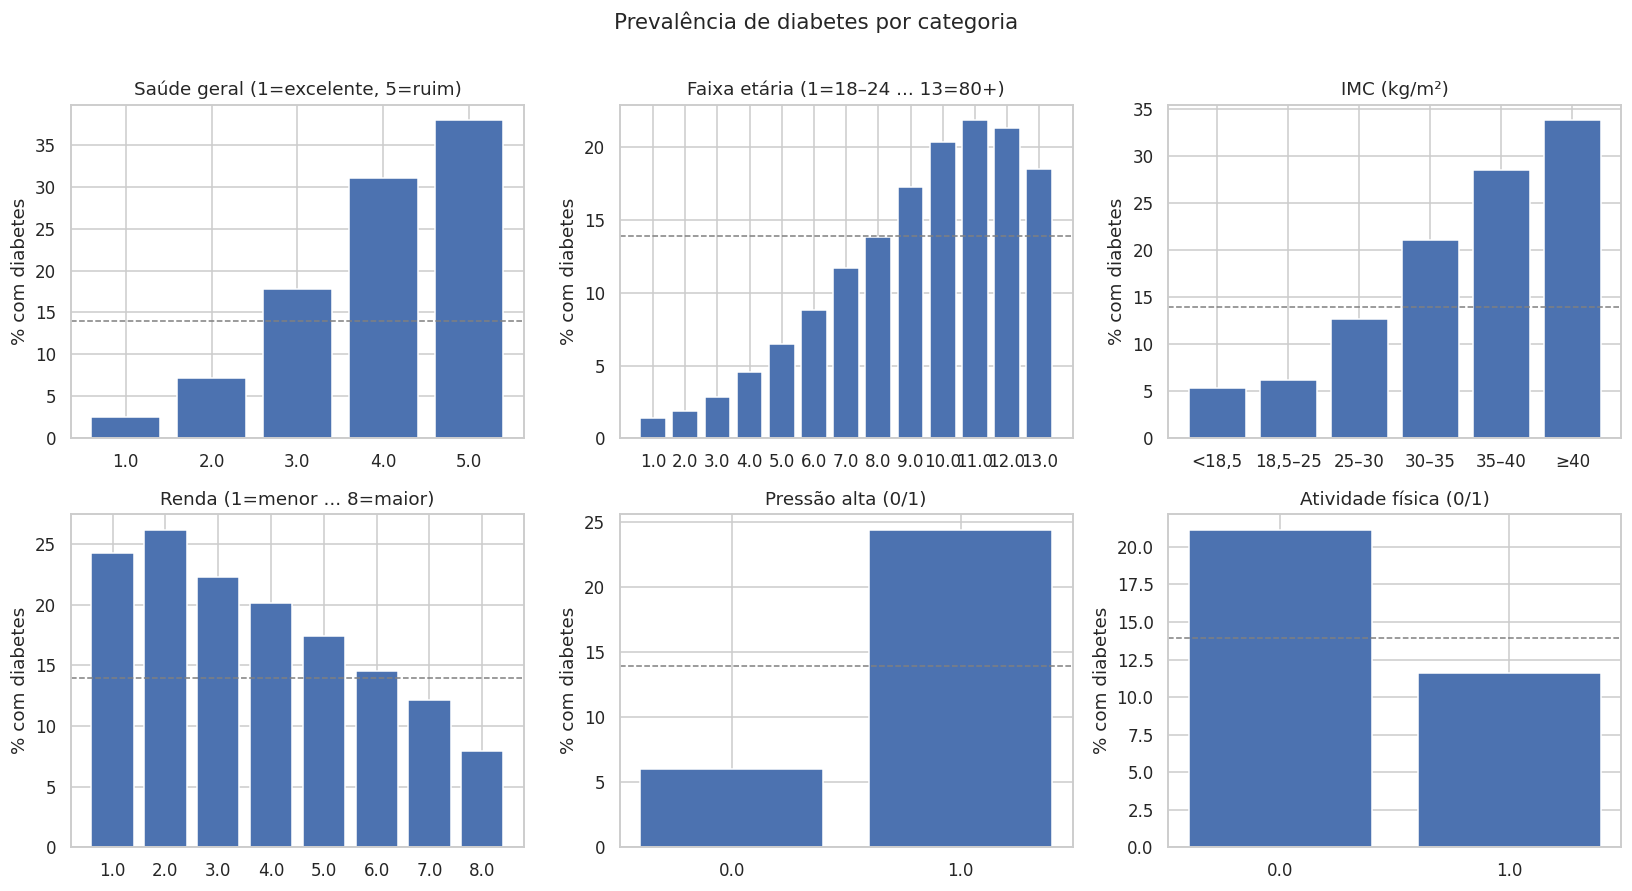

In [5]:
# ============================================================
# 3. Prevalência de diabetes por categoria das principais variáveis
# ============================================================
# Leitura: cada barra mostra a % de pessoas COM diabetes naquele grupo.
# A linha tracejada é a prevalência geral (~14%).
plot_df = df.copy()
plot_df["BMI_faixa"] = pd.cut(plot_df["BMI"], bins=[0, 18.5, 25, 30, 35, 40, 100],
                              labels=["<18,5", "18,5–25", "25–30", "30–35", "35–40", "≥40"])
variaveis = {"GenHlth": "Saúde geral (1=excelente, 5=ruim)",
             "Age": "Faixa etária (1=18–24 ... 13=80+)",
             "BMI_faixa": "IMC (kg/m²)",
             "Income": "Renda (1=menor ... 8=maior)",
             "HighBP": "Pressão alta (0/1)",
             "PhysActivity": "Atividade física (0/1)"}
prev_geral = df[TARGET].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, titulo) in zip(axes.ravel(), variaveis.items()):
    prev = plot_df.groupby(col, observed=True)[TARGET].mean() * 100
    ax.bar(prev.index.astype(str), prev.values, color="#4C72B0")
    ax.axhline(prev_geral * 100, ls="--", color="gray", lw=1)
    ax.set_title(titulo); ax.set_ylabel("% com diabetes")
plt.suptitle("Prevalência de diabetes por categoria", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

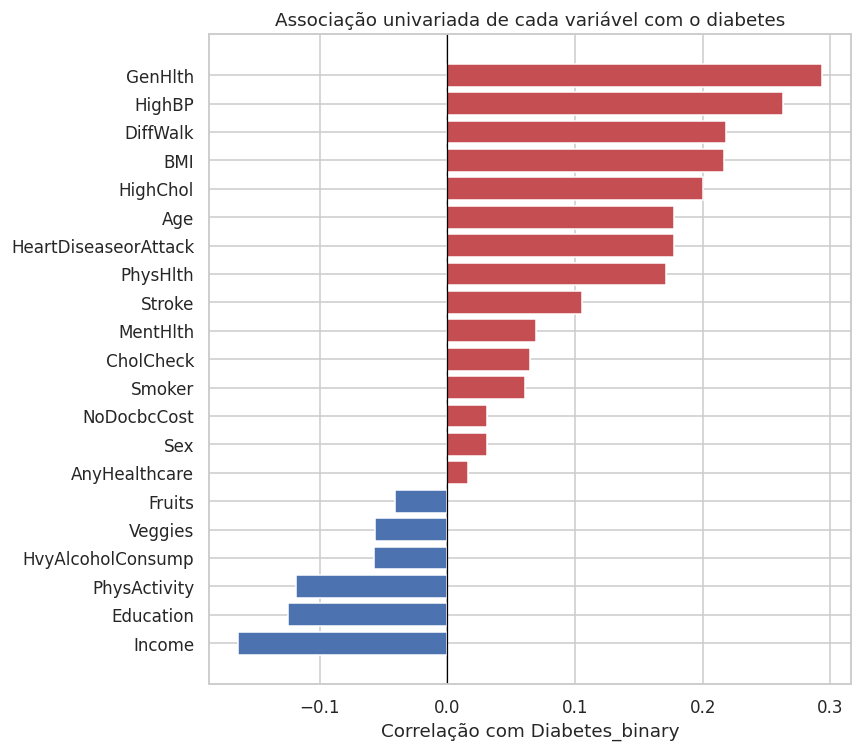

GenHlth                 0.294
HighBP                  0.263
DiffWalk                0.218
BMI                     0.217
HighChol                0.200
Age                     0.177
HeartDiseaseorAttack    0.177
PhysHlth                0.171
Stroke                  0.106
MentHlth                0.069
CholCheck               0.065
Smoker                  0.061
NoDocbcCost             0.031
Sex                     0.031
AnyHealthcare           0.016
Fruits                 -0.041
Veggies                -0.057
HvyAlcoholConsump      -0.057
PhysActivity           -0.118
Education              -0.124
Income                 -0.164


In [6]:
# ============================================================
# 4. Correlação de cada variável com o alvo
# ============================================================
# Com o alvo binário, a correlação de Pearson equivale à correlação ponto-bisserial.
# É só uma medida de associação LINEAR e univariada: não captura interações nem causalidade.
corr_alvo = df.corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
cores = ["#C44E52" if v > 0 else "#4C72B0" for v in corr_alvo.values]
ax.barh(corr_alvo.index, corr_alvo.values, color=cores)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlação com Diabetes_binary")
ax.set_title("Associação univariada de cada variável com o diabetes")
plt.tight_layout(); plt.show()
print(corr_alvo.sort_values(ascending=False).round(3).to_string())

**O que eu aprendi com a exploração**

- **Qualidade:** 253.680 respostas, 21 preditoras, **nenhum valor ausente**. Todas as variáveis já são numéricas: 14 binárias, 4 ordinais (`GenHlth`, `Age`, `Education`, `Income`) e 3 numéricas (`BMI`, `MentHlth` e `PhysHlth`, essas duas últimas em "dias de saúde ruim no último mês").
- **Desbalanceamento:** só **13,9%** das pessoas têm diabetes. Isso significa que um modelo "preguiçoso", que responde sempre "sem diabetes", já acertaria ~86% dos casos. **Por isso, acurácia não será minha métrica principal.**
- **Gradientes claros de risco:** a prevalência sobe de ~2% (saúde geral excelente) para ~38% (saúde ruim), de ~5% (IMC normal) para ~33% (IMC ≥ 40) e de ~6% para ~24% entre quem tem pressão alta. Renda e atividade física têm associação inversa (o diabetes é mais comum entre quem tem menor renda e entre sedentários).
- **Idade:** a prevalência sobe até as faixas de 65–74 anos e cai um pouco na faixa 80+, o que pode refletir **viés de sobrevivência** (pessoas com diabetes têm maior mortalidade e chegam menos a essa idade).
- **Correlações:** as maiores associações univariadas são com saúde geral (0,29), pressão alta (0,26), dificuldade para caminhar (0,22), IMC (0,22) e colesterol alto (0,20). São correlações modestas individualmente, o que sugere que o desempenho vai depender da **combinação** das variáveis, que é justamente onde uma rede neural pode ajudar.
- **Duplicatas (9,5%):** com variáveis quase todas categóricas, é esperado que **pessoas diferentes deem respostas idênticas**. Como não há identificador de respondente, eu **mantive** essas linhas, porque removê-las distorceria a distribuição real das respostas.

> ⚠️ **Cuidado na interpretação:** o BRFSS é um estudo **transversal** e **autorrelatado**. Variáveis como "saúde geral ruim" ou "dificuldade para caminhar" podem ser **consequência** do diabetes, e não causa. O modelo aprende associações úteis para rastreio, não relações causais.

### 2.3 Preparação dos dados

1. **Divisão estratificada** em treino (70%), validação (15%) e teste (15%), mantendo a prevalência de ~14% em todas as partes. A validação serve para escolher hiperparâmetros e o limiar; o **teste só é usado uma vez, no final**.
2. **Padronização** (média 0, desvio 1) das 7 variáveis não binárias, com o `StandardScaler` ajustado **apenas no treino** e depois aplicado à validação e ao teste. Assim eu evito *vazamento de dados* (o modelo "espiar" informações do teste). As binárias ficam em 0/1.
3. **Pesos de classe:** calculo pesos inversamente proporcionais à frequência de cada classe, para que errar um caso de diabetes "custe" mais na função de perda durante o treino.

In [7]:
# ============================================================
# 5. Divisão treino / validação / teste (estratificada)
# ============================================================
X = df.drop(columns=TARGET)
y = df[TARGET].values
FEATURES = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for nome, yy in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:10s}: {len(yy):6d} linhas | prevalência = {yy.mean():.3%}")

# ============================================================
# 6. Padronização (ajustada SÓ no treino -> sem vazamento)
# ============================================================
cols_escalar = [c for c in FEATURES if X[c].nunique() > 2]
print("\nVariáveis padronizadas:", cols_escalar)

scaler = StandardScaler().fit(X_train[cols_escalar])
def preparar(X_):
    X_ = X_.copy()
    X_[cols_escalar] = scaler.transform(X_[cols_escalar])
    return X_.astype("float32").values

Xtr, Xva, Xte = preparar(X_train), preparar(X_val), preparar(X_test)
print("Shapes:", Xtr.shape, Xva.shape, Xte.shape)

# ============================================================
# 7. Pesos de classe
# ============================================================
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: pesos[0], 1: pesos[1]}
print("Pesos de classe:", {k: round(v, 3) for k, v in class_weight.items()})

Treino    : 177576 linhas | prevalência = 13.933%
Validação :  38052 linhas | prevalência = 13.934%
Teste     :  38052 linhas | prevalência = 13.934%

Variáveis padronizadas: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']
Shapes: (177576, 21) (38052, 21) (38052, 21)
Pesos de classe: {0: np.float64(0.581), 1: np.float64(3.589)}


### 2.4 Métricas de avaliação

Como os dados são desbalanceados, eu avalio os modelos com um conjunto de métricas, cada uma respondendo a uma pergunta diferente (a mesma lógica da validação de instrumentos de rastreio):

| Métrica | Pergunta que responde |
|---|---|
| **ROC-AUC** | Qual a chance de o modelo dar uma probabilidade maior a uma pessoa com diabetes do que a uma sem? (independe do limiar) |
| **PR-AUC** (*average precision*) | Quão bem o modelo encontra os positivos mantendo a precisão? Mais sensível ao desbalanceamento (o acaso aqui vale ~0,14, e não 0,5) |
| **Sensibilidade** (*recall*) | Dos que têm diabetes, quantos o modelo detecta? |
| **Especificidade** | Dos que não têm, quantos o modelo descarta corretamente? |
| **Precisão** (VPP) | Dos que o modelo aponta como positivos, quantos realmente têm diabetes? |
| **F1** | Média harmônica entre precisão e sensibilidade |

### 2.5 Baselines

Antes da rede neural, eu treino duas referências:
- **Classificador "sempre negativo":** mostra o tamanho da armadilha da acurácia.
- **Regressão logística:** é, na prática, **uma rede neural com um único neurônio e ativação sigmoide** (o perceptron do Módulo 1 com saída probabilística). Se a MLP não superar a logística, as camadas ocultas não estão agregando nada.

In [8]:
# ============================================================
# 8. Função de avaliação (reaproveitada em todo o notebook)
# ============================================================
def avaliar(y_true, prob, limiar=0.5, nome="modelo"):
    pred = (prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"modelo": nome,
            "ROC-AUC": roc_auc_score(y_true, prob),
            "PR-AUC": average_precision_score(y_true, prob),
            "Acurácia": accuracy_score(y_true, pred),
            "Sensibilidade": tp / (tp + fn),
            "Especificidade": tn / (tn + fp),
            "Precisão": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "limiar": limiar}

# Baseline 1: sempre prevê "sem diabetes" (probabilidade = 0 para todos)
res_dummy = avaliar(y_val, np.zeros_like(y_val, dtype=float), nome="Sempre negativo")

# Baseline 2: regressão logística com os mesmos pesos de classe
t0 = time.time()
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
logreg.fit(Xtr, y_train)
prob_lr_val = logreg.predict_proba(Xva)[:, 1]
res_lr = avaliar(y_val, prob_lr_val, nome="Regressão logística")
print(f"Regressão logística treinada em {time.time()-t0:.1f}s")

pd.DataFrame([res_dummy, res_lr]).set_index("modelo").round(3)

Regressão logística treinada em 2.6s


,ROC-AUC,PR-AUC,Acurácia,Sensibilidade,Especificidade,Precisão,F1,limiar
modelo,,,,,,,,
Sempre negativo,0.500,0.139,0.861,0.000,1.000,0.00,0.00,0.5
Regressão logística,0.821,0.402,0.730,0.761,0.725,0.31,0.44,0.5


### 2.6 A rede neural (MLP)

**Arquitetura base:** entrada com 21 variáveis → 3 camadas ocultas densas (**256 → 128 → 64 neurônios**, ativação **ReLU**) → 1 neurônio de saída com **sigmoide**, que devolve a probabilidade de diabetes.

- **ReLU** nas camadas ocultas: é simples de calcular e não "satura" para valores positivos, o que evita o desaparecimento do gradiente durante o *backpropagation*.
- **Sigmoide** na saída: comprime o resultado entre 0 e 1, permitindo interpretá-lo como probabilidade.
- **Função de perda:** entropia cruzada binária (*binary cross-entropy*), ponderada pelos pesos de classe.
- **Otimizador padrão:** Adam (taxa de aprendizado 0,001), *batch* de 1024 exemplos.

Eu escolhi de propósito uma rede **maior do que o necessário** para 21 variáveis (~47 mil parâmetros), porque assim fica possível observar o sobreajuste (*overfitting*) e medir o quanto cada técnica de regularização ajuda a controlá-lo.

**Um cuidado técnico importante:** como eu uso pesos de classe no treino, a perda de treino fica "ponderada". Se a perda de validação não fosse ponderada da mesma forma, as duas curvas estariam em escalas diferentes e a comparação treino × validação seria enganosa. Por isso, eu também passo pesos para os exemplos de validação.

### 2.7 Experimentos de regularização (ablação)

Para medir a **contribuição efetiva** de cada estratégia, eu treino a mesma arquitetura mudando **uma coisa de cada vez**:

| Exp. | Configuração | O que eu quero observar |
|---|---|---|
| A | Sem regularização, 60 épocas fixas | O sobreajuste "puro" |
| B | A + *Early Stopping* | Parar no ponto ótimo resolve? |
| C | B + *Dropout* (30%) | Desligar neurônios aleatoriamente evita "decorar" o treino? |
| D | B + L2 (λ = 10⁻⁴) | Penalizar pesos grandes suaviza o modelo? |
| E | B + *Batch Normalization* | Normalizar as ativações estabiliza e acelera o treino? |
| F | B + Dropout + L2 + BatchNorm | Combinar tudo ajuda ou atrapalha? |

In [9]:
# ============================================================
# 9. Funções para construir e treinar a MLP
# ============================================================
N_FEATURES = Xtr.shape[1]
class_weight = {k: float(v) for k, v in class_weight.items()}   # Keras prefere float puro
# pesos por exemplo na validação -> perdas de treino e validação na MESMA escala
sw_val = np.where(y_val == 1, class_weight[1], class_weight[0]).astype("float32")

def construir_mlp(camadas=(256, 128, 64), dropout=0.0, l2=0.0, batchnorm=False,
                  otimizador="adam", lr=1e-3, nome="mlp"):
    keras.utils.set_random_seed(SEED)           # mesma inicialização em todos os experimentos
    reg = regularizers.l2(l2) if l2 > 0 else None
    entrada = keras.Input(shape=(N_FEATURES,))
    x = entrada
    for n in camadas:
        # use_bias=False quando há BatchNorm, porque o BN já tem seu próprio deslocamento (beta)
        x = layers.Dense(n, kernel_regularizer=reg, use_bias=not batchnorm)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    saida = layers.Dense(1, activation="sigmoid")(x)
    modelo = keras.Model(entrada, saida, name=nome)

    opt = {"adam": keras.optimizers.Adam(learning_rate=lr),
           "sgd": keras.optimizers.SGD(learning_rate=lr),
           "momentum": keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
           "rmsprop": keras.optimizers.RMSprop(learning_rate=lr)}[otimizador]
    modelo.compile(optimizer=opt, loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc"),
                            keras.metrics.AUC(curve="PR", name="pr_auc")])
    return modelo

def treinar(modelo, epocas=60, early_stopping=True, paciencia=8, batch=1024):
    cbs = []
    if early_stopping:
        # monitora a perda de validação e devolve os pesos da MELHOR época
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                                 restore_best_weights=True))
    t0 = time.time()
    hist = modelo.fit(Xtr, y_train, validation_data=(Xva, y_val, sw_val),
                      epochs=epocas, batch_size=batch, class_weight=class_weight,
                      callbacks=cbs, verbose=0)
    return hist.history, time.time() - t0

m = construir_mlp()
m.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,849 (183.00 KB)

 Trainable params: 46,849 (183.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ============================================================
# 10. Ablação: treina os 6 experimentos (leva alguns minutos em CPU)
# ============================================================
experimentos = {
    "A: sem regularização": dict(cfg={}, es=False),
    "B: Early Stopping":    dict(cfg={}, es=True),
    "C: ES + Dropout":      dict(cfg={"dropout": 0.3}, es=True),
    "D: ES + L2":           dict(cfg={"l2": 1e-4}, es=True),
    "E: ES + BatchNorm":    dict(cfg={"batchnorm": True}, es=True),
    "F: ES + Drop + L2 + BN": dict(cfg={"dropout": 0.3, "l2": 1e-4, "batchnorm": True}, es=True),
}

historicos, modelos, resultados = {}, {}, []
for nome, e in experimentos.items():
    modelo = construir_mlp(**e["cfg"])
    hist, dur = treinar(modelo, early_stopping=e["es"])
    prob = modelo.predict(Xva, batch_size=4096, verbose=0).ravel()
    r = avaliar(y_val, prob, nome=nome)
    melhor_ep = int(np.argmin(hist["val_loss"])) + 1
    r.update({"épocas treinadas": len(hist["loss"]), "melhor época": melhor_ep,
              "perda treino (fim)": hist["loss"][-1], "perda val (mín)": min(hist["val_loss"]),
              "tempo (s)": dur})
    historicos[nome], modelos[nome] = hist, modelo
    resultados.append(r)
    print(f"{nome:26s} | épocas={len(hist['loss']):2d} (melhor={melhor_ep:2d}) | "
          f"ROC-AUC val={r['ROC-AUC']:.4f} | PR-AUC val={r['PR-AUC']:.4f} | {dur:.0f}s")

A: sem regularização       | épocas=60 (melhor= 5) | ROC-AUC val=0.7737 | PR-AUC val=0.3404 | 137s
B: Early Stopping          | épocas=13 (melhor= 5) | ROC-AUC val=0.8269 | PR-AUC val=0.4242 | 32s
C: ES + Dropout            | épocas=21 (melhor=13) | ROC-AUC val=0.8289 | PR-AUC val=0.4288 | 70s
D: ES + L2                 | épocas=23 (melhor=15) | ROC-AUC val=0.8280 | PR-AUC val=0.4260 | 56s
E: ES + BatchNorm          | épocas=11 (melhor= 3) | ROC-AUC val=0.8259 | PR-AUC val=0.4215 | 42s
F: ES + Drop + L2 + BN     | épocas=36 (melhor=28) | ROC-AUC val=0.8288 | PR-AUC val=0.4290 | 159s


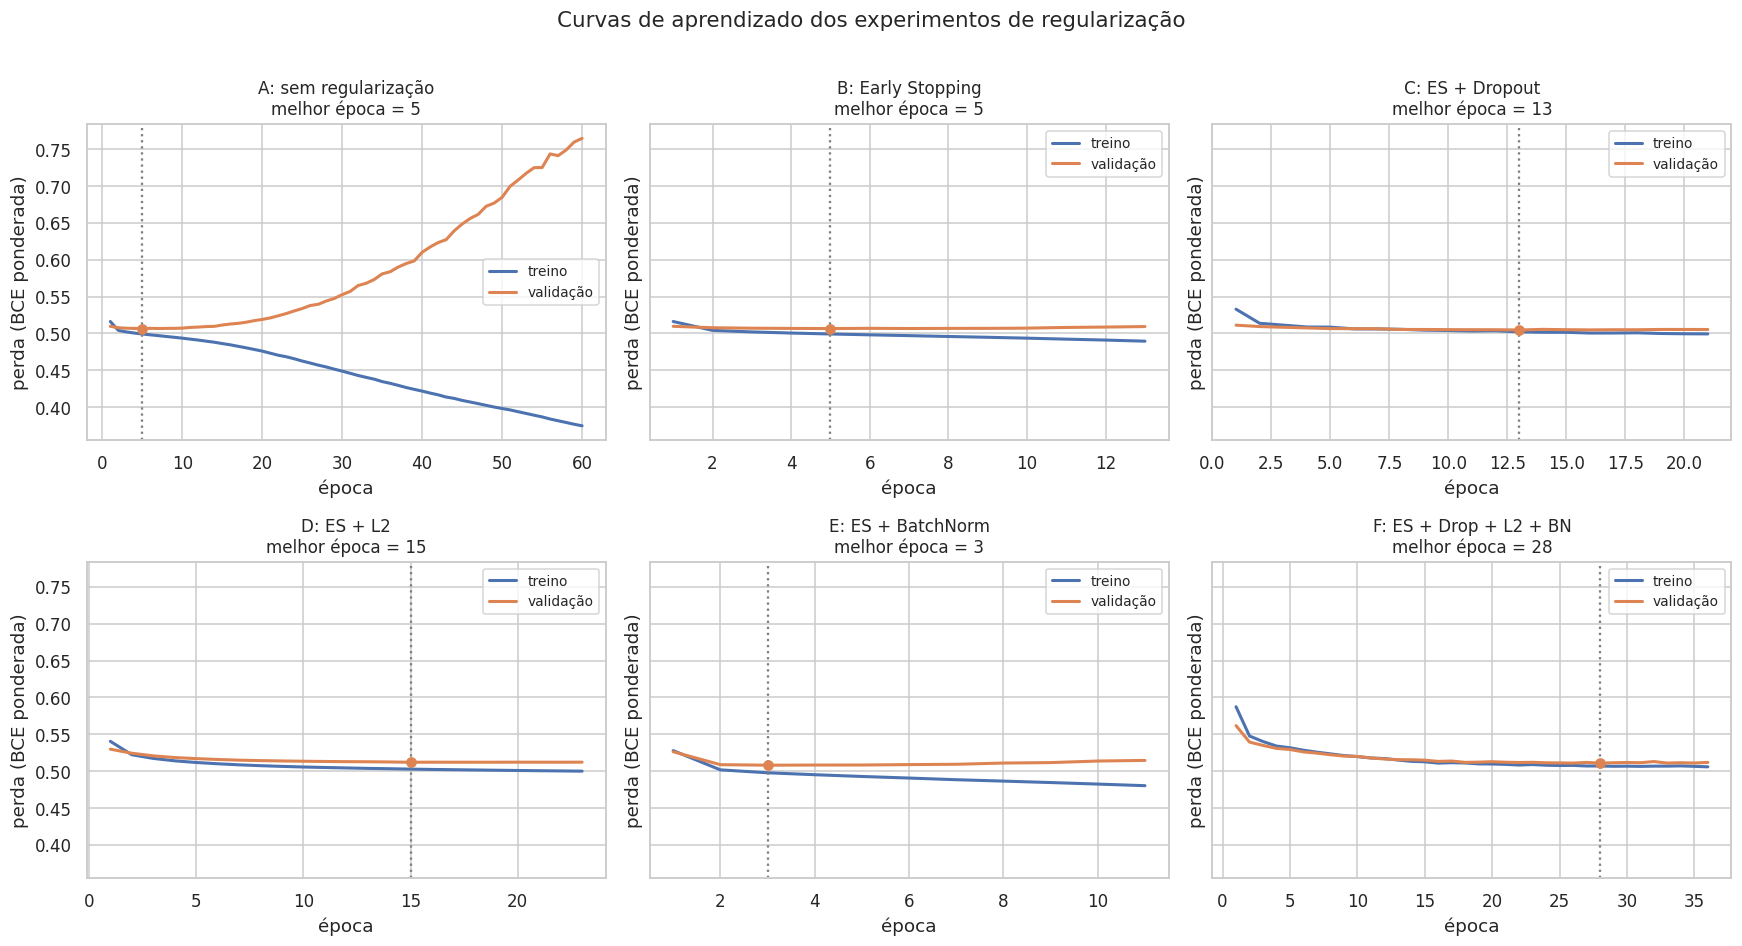

In [11]:
# ============================================================
# 11. Curvas de aprendizado: perda de treino x validação
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
for ax, (nome, h) in zip(axes.ravel(), historicos.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], label="treino", color="#4C72B0", lw=2)
    ax.plot(ep, h["val_loss"], label="validação", color="#DD8452", lw=2)
    best = int(np.argmin(h["val_loss"])) + 1
    ax.axvline(best, ls=":", color="gray")
    ax.scatter(best, min(h["val_loss"]), color="#DD8452", zorder=5)
    ax.set_title(f"{nome}\nmelhor época = {best}", fontsize=11)
    ax.set_xlabel("época"); ax.set_ylabel("perda (BCE ponderada)")
    ax.legend(fontsize=9)
plt.suptitle("Curvas de aprendizado dos experimentos de regularização", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

,ROC-AUC,PR-AUC,Sensibilidade,Especificidade,F1,épocas treinadas,melhor época,perda treino (fim),perda val (mín),tempo (s),gap treino-val
modelo,,,,,,,,,,,
Regressão logística,0.8215,0.4020,0.7608,0.7252,0.4400,NaN,NaN,NaN,NaN,NaN,NaN
A: sem regularização,0.7737,0.3404,0.6232,0.7742,0.4129,60.0,5.0,0.3748,0.5067,136.5211,-0.1319
B: Early Stopping,0.8269,0.4242,0.7963,0.7045,0.4398,13.0,5.0,0.4896,0.5067,31.7882,-0.0171
C: ES + Dropout,0.8289,0.4288,0.8065,0.6965,0.4381,21.0,13.0,0.4994,0.5047,70.4428,-0.0053
D: ES + L2,0.8280,0.4260,0.8084,0.6911,0.4351,23.0,15.0,0.5001,0.5121,55.9654,-0.0121
E: ES + BatchNorm,0.8259,0.4215,0.8023,0.6941,0.4347,11.0,3.0,0.4804,0.5081,41.5696,-0.0278
F: ES + Drop + L2 + BN,0.8288,0.4290,0.8214,0.6797,0.4323,36.0,28.0,0.5059,0.5109,159.2873,-0.0050


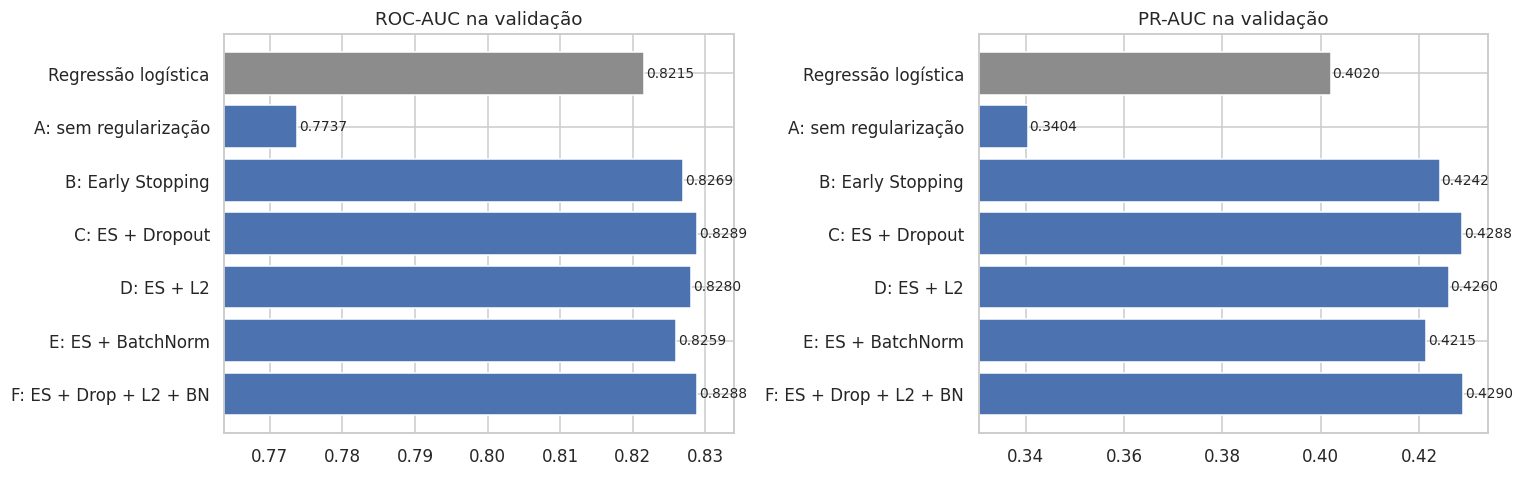

In [12]:
# ============================================================
# 12. Tabela-resumo da ablação (validação)
# ============================================================
tab_abl = pd.DataFrame([res_lr] + resultados).set_index("modelo")
cols_show = ["ROC-AUC", "PR-AUC", "Sensibilidade", "Especificidade", "F1",
             "épocas treinadas", "melhor época", "perda treino (fim)", "perda val (mín)", "tempo (s)"]
tab_abl["gap treino-val"] = tab_abl["perda treino (fim)"] - tab_abl["perda val (mín)"]
display(tab_abl[cols_show + ["gap treino-val"]].round(4))

# Gráfico comparando ROC-AUC e PR-AUC de validação
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, met in zip(axes, ["ROC-AUC", "PR-AUC"]):
    vals = tab_abl[met]
    cores = ["#8C8C8C"] + ["#4C72B0"] * (len(vals) - 1)
    ax.barh(vals.index[::-1], vals.values[::-1], color=cores[::-1])
    ax.set_xlim(vals.min() - 0.01, vals.max() + 0.005)
    for i, v in enumerate(vals.values[::-1]):
        ax.text(v + 0.0003, i, f"{v:.4f}", va="center", fontsize=9)
    ax.set_title(f"{met} na validação")
plt.tight_layout(); plt.show()

**O que os experimentos de regularização mostram**

- **A (sem regularização) — sobreajuste clássico.** A perda de validação atinge o mínimo (0,507) já na **5ª época** e depois **sobe sem parar** (até ~0,77), enquanto a perda de treino continua caindo (até 0,37). A rede passa a **decorar o conjunto de treino** em vez de aprender o padrão geral, como alguém que decora as respostas de um teste em vez de aprender o construto. O resultado é um ROC-AUC de **0,774**, **pior até que a regressão logística** (0,821).
- **B (Early Stopping) — a maior contribuição isolada.** Só por parar no ponto certo e restaurar os pesos da melhor época, o ROC-AUC sobe de 0,774 para **0,827** (+0,053), com um treino cerca de 4 vezes mais curto (13 épocas em vez de 60).
- **C (Dropout 30%) — melhor ROC-AUC (0,829).** O principal efeito é **adiar o sobreajuste**: a melhor época passa da 5ª para a 13ª, ou seja, a rede consegue aprender por mais tempo antes de começar a decorar. Nas primeiras épocas a perda de treino fica **acima** da de validação porque o Dropout só é aplicado durante o treino (na validação, todos os neurônios estão ativos).
- **D (L2)** tem efeito parecido (0,828; melhor época 15): penalizar pesos grandes deixa a função aprendida mais suave.
- **E (Batch Normalization)** faz a rede **convergir mais rápido** (melhor época = 3), mas **não melhora o desempenho** (0,826). Isso faz sentido, porque o BN foi pensado para estabilizar e acelerar o treino, e o efeito regularizador dele é secundário.
- **F (tudo combinado)** chega ao mesmo nível do Dropout sozinho (0,829), mas precisa de **36 épocas**, o maior custo entre as configurações regularizadas. As regularizações **não se somam**: depois que o sobreajuste é controlado, empilhar técnicas só aumenta o custo.

**Leitura crítica:** depois do Early Stopping, as diferenças entre C, D, E e F são da ordem de **0,001–0,003** de ROC-AUC, o que provavelmente está dentro da variação que teríamos só trocando a semente aleatória. A conclusão robusta é: **controlar o sobreajuste é essencial; a técnica específica importa pouco neste problema.**

Comparando com o baseline, a melhor MLP supera a regressão logística em **+0,007 de ROC-AUC** e **+0,027 de PR-AUC**. O ganho existe, mas é modesto. Isso sugere que boa parte da relação entre as variáveis e o diabetes é **aproximadamente aditiva**, e que a capacidade extra da rede para capturar interações não lineares traz um benefício limitado nesses dados.

### 2.8 Comparação de otimizadores

Mantendo a melhor configuração de regularização da ablação, eu comparo os otimizadores vistos no Módulo 2:

- **SGD** (taxa 0,01): dá passos proporcionais ao gradiente do *mini-batch*.
- **SGD + Momentum** (0,9): acumula uma "velocidade" na direção dos gradientes anteriores, como uma bola descendo uma ladeira, o que reduz as oscilações.
- **RMSProp** (0,001): adapta a taxa de aprendizado de cada peso dividindo pelo histórico recente da magnitude dos gradientes.
- **Adam** (0,001): combina Momentum e RMSProp.

Configuração usada: C: ES + Dropout {'dropout': 0.3}
SGD (lr=0,01)              | melhor época=60 | ROC-AUC val=0.8244 | 190s
SGD + Momentum (lr=0,01)   | melhor época=60 | ROC-AUC val=0.8284 | 197s
RMSProp (lr=0,001)         | melhor época=18 | ROC-AUC val=0.8288 | 86s
Adam (lr=0,001)            | melhor época=13 | ROC-AUC val=0.8289 | 72s


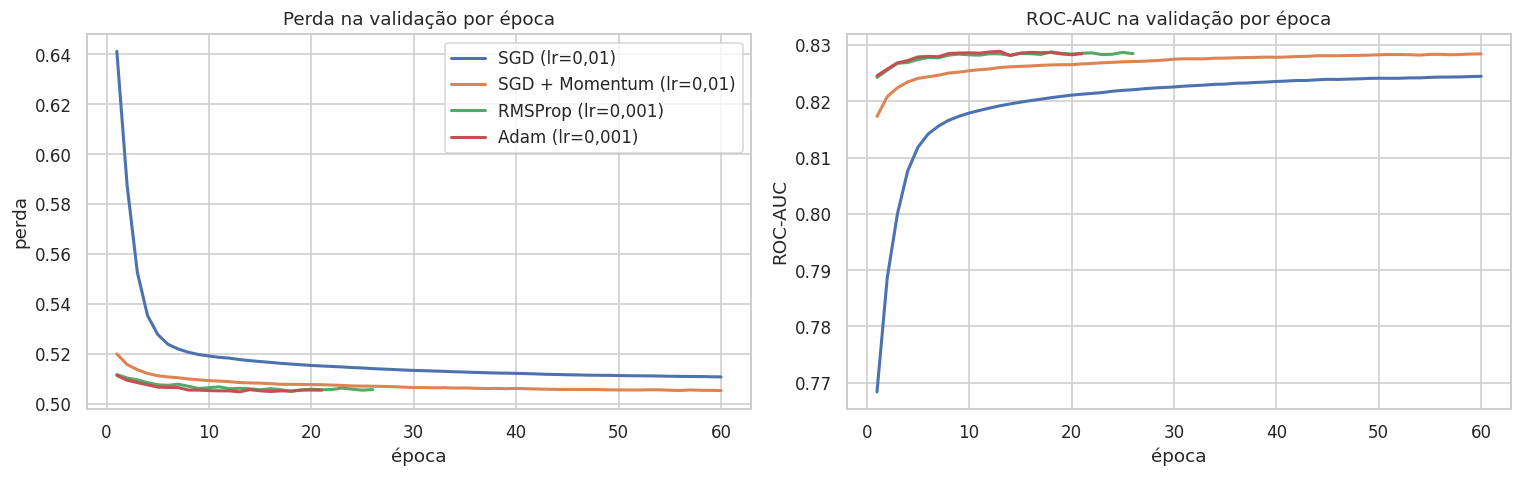

,ROC-AUC,PR-AUC,épocas treinadas,melhor época,perda val (mín),tempo (s)
modelo,,,,,,
"SGD (lr=0,01)",0.8244,0.4187,60,60,0.5107,190.3064
"SGD + Momentum (lr=0,01)",0.8284,0.4271,60,60,0.5052,196.7225
"RMSProp (lr=0,001)",0.8288,0.4290,26,18,0.5049,86.2320
"Adam (lr=0,001)",0.8289,0.4288,21,13,0.5047,71.5358


In [13]:
# ============================================================
# 13. Comparação de otimizadores (mesma arquitetura e regularização)
# ============================================================
melhor_nome = tab_abl.drop("Regressão logística")["ROC-AUC"].idxmax()
cfg_melhor = experimentos[melhor_nome]["cfg"]
print("Configuração usada:", melhor_nome, cfg_melhor)

otimizadores = {"SGD (lr=0,01)": ("sgd", 1e-2),
                "SGD + Momentum (lr=0,01)": ("momentum", 1e-2),
                "RMSProp (lr=0,001)": ("rmsprop", 1e-3),
                "Adam (lr=0,001)": ("adam", 1e-3)}
hist_opt, modelos_opt, res_opt = {}, {}, []
for nome, (opt, lr) in otimizadores.items():
    modelo = construir_mlp(**cfg_melhor, otimizador=opt, lr=lr)
    hist, dur = treinar(modelo, epocas=60, paciencia=8)
    prob = modelo.predict(Xva, batch_size=4096, verbose=0).ravel()
    r = avaliar(y_val, prob, nome=nome)
    r.update({"épocas treinadas": len(hist["loss"]),
              "melhor época": int(np.argmin(hist["val_loss"])) + 1,
              "perda val (mín)": min(hist["val_loss"]), "tempo (s)": dur})
    hist_opt[nome], modelos_opt[nome] = hist, modelo
    res_opt.append(r)
    print(f"{nome:26s} | melhor época={r['melhor época']:2d} | ROC-AUC val={r['ROC-AUC']:.4f} | {dur:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nome, h in hist_opt.items():
    axes[0].plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], lw=2, label=nome)
    axes[1].plot(np.arange(1, len(h["val_auc"]) + 1), h["val_auc"], lw=2, label=nome)
axes[0].set_title("Perda na validação por época"); axes[0].set_xlabel("época"); axes[0].set_ylabel("perda")
axes[1].set_title("ROC-AUC na validação por época"); axes[1].set_xlabel("época"); axes[1].set_ylabel("ROC-AUC")
axes[0].legend(); plt.tight_layout(); plt.show()

pd.DataFrame(res_opt).set_index("modelo")[["ROC-AUC", "PR-AUC", "épocas treinadas",
                                           "melhor época", "perda val (mín)", "tempo (s)"]].round(4)

**O que a comparação de otimizadores mostra**

- **SGD e SGD + Momentum não convergiram em 60 épocas:** a melhor época foi justamente a última, ou seja, a perda de validação ainda estava caindo quando o treino acabou. O Momentum acelera bastante (ROC-AUC 0,828 × 0,824 do SGD puro no mesmo número de épocas), porque acumula "velocidade" nas direções consistentes do gradiente.
- **RMSProp e Adam convergiram muito mais rápido** (melhores épocas 18 e 13), porque ajustam a taxa de aprendizado de cada peso individualmente.
- **O desempenho final é parecido** (0,828–0,829 para Momentum, RMSProp e Adam). A diferença principal está na **eficiência**: o Adam chega ao mesmo resultado em cerca de um terço do tempo do SGD. Por isso eu mantive o **Adam** no modelo final. A escolha é justificada pela velocidade e estabilidade, não por uma acurácia maior.

### 2.9 Escolha do limiar de decisão

Por padrão, um classificador considera "positivo" quem tem probabilidade ≥ 0,5. Mas, assim como os **pontos de corte** de um instrumento de rastreio, esse limiar é uma escolha: baixá-lo aumenta a sensibilidade e reduz a especificidade, e vice-versa. Eu escolho o limiar **na validação** pelo **índice de Youden** (J = sensibilidade + especificidade − 1), que busca o melhor equilíbrio entre os dois, e só depois aplico esse limiar no teste.

Modelo final: C: ES + Dropout | otimizador: Adam (lr=0,001)
Limiar de Youden (validação): MLP = 0.495 | Regressão logística = 0.469


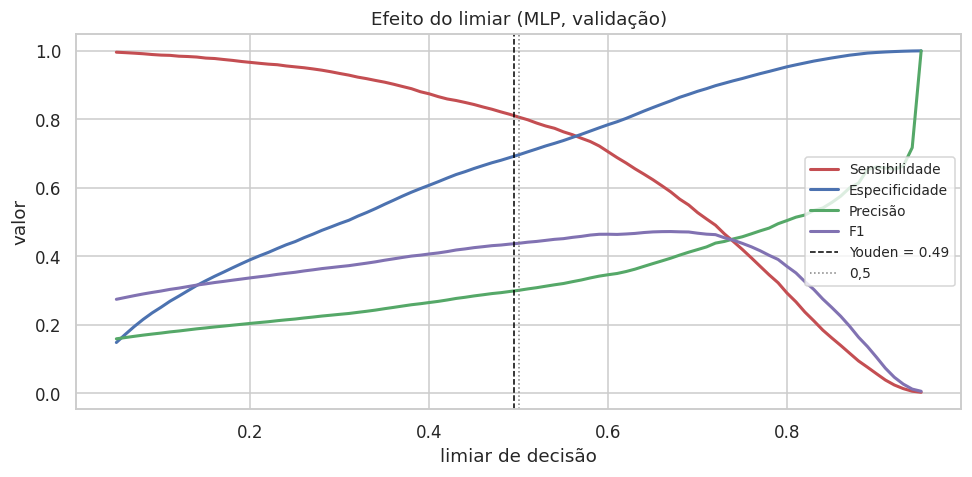

In [14]:
# ============================================================
# 14. Modelo final + escolha do limiar na VALIDAÇÃO
# ============================================================
nome_final = pd.DataFrame(res_opt).set_index("modelo")["ROC-AUC"].idxmax()
modelo_final = modelos_opt[nome_final]
print(f"Modelo final: {melhor_nome} | otimizador: {nome_final}")

def limiar_youden(y_true, prob):
    fpr, tpr, thr = roc_curve(y_true, prob)
    j = tpr - fpr
    return thr[np.argmax(j)]

prob_mlp_val = modelo_final.predict(Xva, batch_size=4096, verbose=0).ravel()
lim_mlp = limiar_youden(y_val, prob_mlp_val)
lim_lr = limiar_youden(y_val, prob_lr_val)
print(f"Limiar de Youden (validação): MLP = {lim_mlp:.3f} | Regressão logística = {lim_lr:.3f}")

# Como sensibilidade, especificidade e precisão variam com o limiar (validação)
lims = np.linspace(0.05, 0.95, 91)
curvas = pd.DataFrame([avaliar(y_val, prob_mlp_val, l) for l in lims])
fig, ax = plt.subplots(figsize=(9, 4.5))
for met, cor in [("Sensibilidade", "#C44E52"), ("Especificidade", "#4C72B0"), ("Precisão", "#55A868"), ("F1", "#8172B2")]:
    ax.plot(curvas["limiar"], curvas[met], lw=2, label=met, color=cor)
ax.axvline(lim_mlp, ls="--", color="black", lw=1, label=f"Youden = {lim_mlp:.2f}")
ax.axvline(0.5, ls=":", color="gray", lw=1, label="0,5")
ax.set_xlabel("limiar de decisão"); ax.set_ylabel("valor"); ax.set_title("Efeito do limiar (MLP, validação)")
ax.legend(loc="center right", fontsize=9); plt.tight_layout(); plt.show()

**Por que o limiar de Youden ficou tão perto de 0,5?** Os pesos de classe já "deslocam" a fronteira de decisão para o ponto de equilíbrio entre as classes, como se o modelo tivesse sido treinado numa população balanceada. Por isso, o limiar ótimo pelo índice de Youden ficou em **0,495** (MLP) e **0,469** (logística). Isso também significa que a saída do modelo **não é uma probabilidade calibrada** para a prevalência real: um valor de 0,5 não quer dizer "50% de chance de ter diabetes".

O gráfico mostra o *trade-off*: se o objetivo fosse priorizar ainda mais a detecção (por exemplo, num rastreio em que perder um caso é muito custoso), eu poderia baixar o limiar e ganhar sensibilidade à custa de especificidade e precisão.

## 3. Resultados no conjunto de teste

Aqui é a primeira (e única) vez que eu uso o conjunto de teste, com o modelo e o limiar já escolhidos na validação.

,ROC-AUC,PR-AUC,Acurácia,Sensibilidade,Especificidade,Precisão,F1,limiar
modelo,,,,,,,,
"Regressão logística (limiar 0,5)",0.822,0.396,0.733,0.763,0.729,0.313,0.444,0.500
Regressão logística (Youden 0.47),0.822,0.396,0.715,0.795,0.703,0.302,0.438,0.469
"MLP (limiar 0,5)",0.830,0.428,0.717,0.810,0.702,0.305,0.443,0.500
MLP (Youden 0.49),0.830,0.428,0.714,0.815,0.697,0.304,0.443,0.495


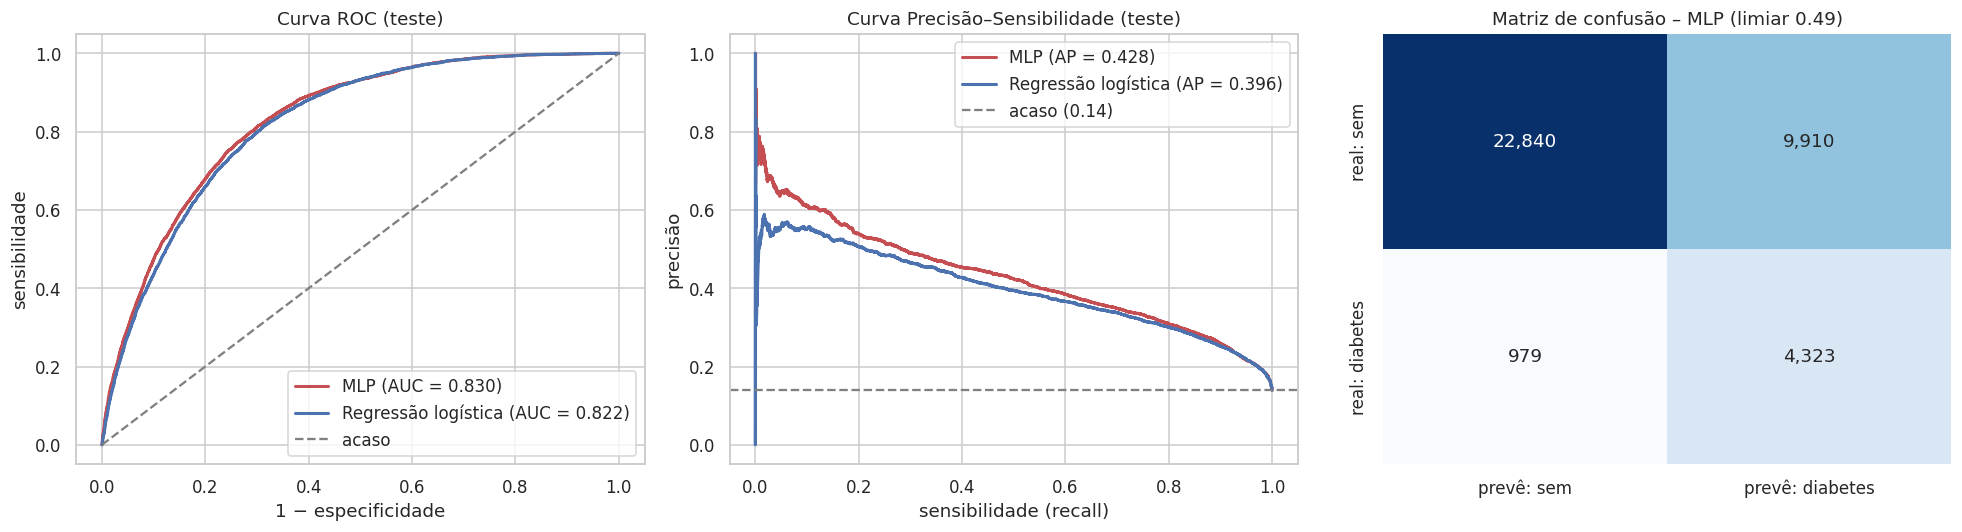

In [15]:
# ============================================================
# 15. Avaliação final no TESTE
# ============================================================
prob_mlp_te = modelo_final.predict(Xte, batch_size=4096, verbose=0).ravel()
prob_lr_te = logreg.predict_proba(Xte)[:, 1]

res_teste = pd.DataFrame([
    avaliar(y_test, prob_lr_te, 0.5, "Regressão logística (limiar 0,5)"),
    avaliar(y_test, prob_lr_te, lim_lr, f"Regressão logística (Youden {lim_lr:.2f})"),
    avaliar(y_test, prob_mlp_te, 0.5, "MLP (limiar 0,5)"),
    avaliar(y_test, prob_mlp_te, lim_mlp, f"MLP (Youden {lim_mlp:.2f})"),
]).set_index("modelo")
display(res_teste.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Curva ROC
for nome, p, cor in [("MLP", prob_mlp_te, "#C44E52"), ("Regressão logística", prob_lr_te, "#4C72B0")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, color=cor, label=f"{nome} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="acaso")
axes[0].set_xlabel("1 − especificidade"); axes[0].set_ylabel("sensibilidade"); axes[0].set_title("Curva ROC (teste)"); axes[0].legend()
# Curva precisão-sensibilidade
for nome, p, cor in [("MLP", prob_mlp_te, "#C44E52"), ("Regressão logística", prob_lr_te, "#4C72B0")]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, lw=2, color=cor, label=f"{nome} (AP = {average_precision_score(y_test, p):.3f})")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"acaso ({y_test.mean():.2f})")
axes[1].set_xlabel("sensibilidade (recall)"); axes[1].set_ylabel("precisão"); axes[1].set_title("Curva Precisão–Sensibilidade (teste)"); axes[1].legend()
# Matriz de confusão da MLP com o limiar de Youden
cm = confusion_matrix(y_test, (prob_mlp_te >= lim_mlp).astype(int))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["prevê: sem", "prevê: diabetes"], yticklabels=["real: sem", "real: diabetes"])
axes[2].set_title(f"Matriz de confusão – MLP (limiar {lim_mlp:.2f})")
plt.tight_layout(); plt.show()

In [16]:
# ============================================================
# 15b. Perda e métricas de erro no TESTE (equivalentes às de regressão)
# ============================================================
from sklearn.metrics import log_loss, mean_absolute_error, mean_squared_error, r2_score

# Perda do Keras no teste: (1) ponderada, na mesma escala das curvas de treino; (2) sem pesos
sw_test = np.where(y_test == 1, class_weight[1], class_weight[0]).astype("float32")
perda_pond = modelo_final.evaluate(Xte, y_test, sample_weight=sw_test, batch_size=4096, verbose=0)[0]
perda_sem_peso = modelo_final.evaluate(Xte, y_test, batch_size=4096, verbose=0)[0]

# Os pesos de classe multiplicam as "chances" (odds) previstas por w1/w0.
# Para recuperar probabilidades na prevalência real, divido as odds por essa razão.
razao = class_weight[1] / class_weight[0]
def corrigir_prob(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    odds = p / (1 - p) / razao
    return odds / (1 + odds)

def metricas_erro(y, p, nome):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    ll_modelo = -log_loss(y, p, normalize=False)
    ll_nulo = -log_loss(y, np.full_like(p, y_train.mean()), normalize=False)  # modelo "só a prevalência"
    return {"modelo": nome,
            "Perda BCE (sem pesos)": log_loss(y, p),
            "MAE": mean_absolute_error(y, p),
            "MSE (Brier)": mean_squared_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R² (Brier skill score)": r2_score(y, p),
            "Pseudo-R² de McFadden": 1 - ll_modelo / ll_nulo,
            "R² de Tjur": p[y == 1].mean() - p[y == 0].mean()}

m_mlp = metricas_erro(y_test, prob_mlp_te, "MLP")
m_mlp_c = metricas_erro(y_test, corrigir_prob(prob_mlp_te), "MLP (prob. corrigidas)")

print(f"Perda no conjunto de teste (BCE ponderada, mesma escala do treino): {perda_pond:.4f}")
print(f"Perda no conjunto de teste (BCE sem pesos): {perda_sem_peso:.4f}")
print(f"Erro médio absoluto (MAE) no conjunto de teste: {m_mlp_c['MAE']:.4f}")
print(f"Erro quadrático médio (MSE / Brier) no conjunto de teste: {m_mlp_c['MSE (Brier)']:.4f}")
print(f"Raiz do erro quadrático médio (RMSE) no conjunto de teste: {m_mlp_c['RMSE']:.4f}")
print(f"Coeficiente de determinação (R² / Brier skill score): {m_mlp_c['R² (Brier skill score)']:.4f}")
print(f"Pseudo-R² de McFadden: {m_mlp_c['Pseudo-R² de McFadden']:.4f}")
print(f"R² de Tjur (coeficiente de discriminação): {m_mlp_c['R² de Tjur']:.4f}")
print("(MAE, MSE, RMSE e R² calculados com as probabilidades corrigidas para a prevalência real)\n")

tab_erro = pd.DataFrame([
    m_mlp, m_mlp_c,
    metricas_erro(y_test, prob_lr_te, "Regressão logística"),
    metricas_erro(y_test, corrigir_prob(prob_lr_te), "Regressão logística (prob. corrigidas)"),
    metricas_erro(y_test, np.full(len(y_test), y_train.mean()), "Referência: só a prevalência"),
]).set_index("modelo")
display(tab_erro.round(4))

Perda no conjunto de teste (BCE ponderada, mesma escala do treino): 0.5021
Perda no conjunto de teste (BCE sem pesos): 0.5166
Erro médio absoluto (MAE) no conjunto de teste: 0.1944
Erro quadrático médio (MSE / Brier) no conjunto de teste: 0.0969
Raiz do erro quadrático médio (RMSE) no conjunto de teste: 0.3113
Coeficiente de determinação (R² / Brier skill score): 0.1917
Pseudo-R² de McFadden: 0.2264
R² de Tjur (coeficiente de discriminação): 0.1876
(MAE, MSE, RMSE e R² calculados com as probabilidades corrigidas para a prevalência real)



,Perda BCE (sem pesos),MAE,MSE (Brier),RMSE,R² (Brier skill score),Pseudo-R² de McFadden,R² de Tjur
modelo,,,,,,,
MLP,0.5166,0.3384,0.1776,0.4214,-0.4807,-0.2795,0.3253
MLP (prob. corrigidas),0.3124,0.1944,0.0969,0.3113,0.1917,0.2264,0.1876
Regressão logística,0.5269,0.3411,0.1763,0.4199,-0.4704,-0.3050,0.3143
Regressão logística (prob. corrigidas),0.3219,0.1950,0.1002,0.3166,0.1644,0.2027,0.1933
Referência: só a prevalência,0.4038,0.2398,0.1199,0.3463,-0.0000,0.0000,0.0000


**Perda e métricas de erro: como eu adaptei as métricas de regressão**

MAE, MSE, RMSE e R² são métricas de **regressão** (prever um número contínuo). Aqui o alvo é 0 ou 1, então eu as calculo sobre a **probabilidade prevista** p, comparando-a com o valor real y. Nesse caso, elas têm nomes próprios na literatura:

| Métrica | Como interpretar na classificação | MLP (teste) |
|---|---|---|
| **Perda (BCE ponderada)** | Mesma função e escala das curvas de treino; próxima do mínimo da validação (0,505), o que confirma que não houve sobreajuste | **0,502** |
| **MAE** = média de \|y − p\| | Erro médio da probabilidade prevista | **0,194** |
| **MSE** = média de (y − p)², o ***Brier score*** | Mede calibração e discriminação juntas (0 = perfeito) | **0,097** |
| **RMSE** = √MSE | Mesmo que o MSE, na escala da probabilidade | **0,311** |
| **R² (*Brier skill score*)** = 1 − MSE / MSE de referência | Quanto o modelo melhora em relação a "chutar a prevalência" para todos | **0,192** |
| **Pseudo-R² de McFadden** | Melhora da verossimilhança em relação ao modelo nulo; valores entre 0,2 e 0,4 são considerados um bom ajuste | **0,226** |
| **R² de Tjur** | Diferença entre a probabilidade média prevista para quem tem e para quem não tem diabetes | **0,188** |

**Dois cuidados que eu precisei tomar**

1. **As probabilidades "brutas" do modelo estão infladas.** Os pesos de classe fazem o modelo agir como se metade da população tivesse diabetes. Com essas probabilidades, o Brier (0,178) fica **pior** que o da referência (0,120), e o R² fica **negativo** (−0,48), mesmo com o modelo discriminando bem (ROC-AUC 0,830). Por isso eu **corrigi as probabilidades para a prevalência real**, dividindo as *odds* pela razão entre os pesos de classe (w₁/w₀ ≈ 6,2). Depois da correção, todas as métricas de erro superam a referência. A ordenação dos casos não muda, então ROC-AUC, PR-AUC e o limiar continuam os mesmos.
2. **Esses R² não são comparáveis ao R² de 0,90 do projeto de preços de imóveis.** Com um alvo binário, o R² tem um teto natural bem abaixo de 1, porque o modelo só pode dar probabilidades, enquanto o valor real é sempre 0 ou 1. Valores em torno de 0,2 são típicos de bons modelos epidemiológicos com variáveis autorrelatadas.

**MLP × regressão logística:** a MLP tem perda, MAE, Brier, RMSE e McFadden levemente melhores que a logística, e um R² (Brier skill score) de 0,192 contra 0,164. O R² de Tjur é praticamente igual (0,188 × 0,193), o que reforça a conclusão de que a vantagem da rede existe, mas é pequena.

**Como eu leio os resultados no teste**

- **O desempenho se manteve:** ROC-AUC de **0,830** no teste contra 0,829 na validação. Isso indica que o modelo **generaliza** e que eu não "sobreajustei" as escolhas à validação.
- **MLP × regressão logística:** a curva ROC da MLP fica levemente acima em quase todo o trajeto (0,830 × 0,822). A diferença aparece mais na **curva precisão–sensibilidade** (PR-AUC 0,428 × 0,396), principalmente na região de baixa sensibilidade, em que a MLP identifica os casos de maior risco com mais precisão. O PR-AUC da MLP é **~3 vezes o valor do acaso** (0,14).
- **Matriz de confusão (limiar 0,49):** das **5.302 pessoas com diabetes** no teste, o modelo identificou **4.323 (81,5%)** e deixou passar **979**. Em contrapartida, gerou **9.910 falsos positivos**, o que dá cerca de **2,3 falsos positivos para cada verdadeiro positivo** (precisão de 30%).
- **Isso é bom ou ruim?** Depende do uso. Como **instrumento de rastreio** (primeira etapa, seguida de um exame confirmatório barato, como glicemia de jejum ou hemoglobina glicada), alta sensibilidade com precisão moderada é um perfil aceitável. Como **ferramenta diagnóstica**, não seria.
- **A armadilha da acurácia, de novo:** a acurácia da MLP (71%) é **menor** que a do classificador "sempre negativo" (86%), e ainda assim ela é muito mais útil, porque o "sempre negativo" não detecta nenhum caso.

### 3.1 Análise dos erros, desempenho por subgrupo e calibração

Métricas globais escondem detalhes importantes. Aqui eu investigo três perguntas:
1. **Quem o modelo erra?** Comparo o perfil médio das pessoas em cada célula da matriz de confusão (verdadeiros positivos, falsos negativos, falsos positivos e verdadeiros negativos).
2. **O desempenho é igual para todos?** Calculo as métricas separadamente por sexo, faixa etária, IMC e saúde geral.
3. **As probabilidades são confiáveis?** Verifico a calibração das probabilidades corrigidas para a prevalência real, comparando o risco previsto com a proporção observada de diabetes em cada decil.

Médias por grupo (binárias = proporção; GenHlth 1–5; Age 1–13; Income 1–8):


,n,prob,GenHlth,BMI,Age,HighBP,HighChol,DiffWalk,HeartDiseaseorAttack,PhysActivity,Income
grupo,,,,,,,,,,,
VP (diabetes detectado),4323,0.74,3.49,32.87,9.58,0.84,0.72,0.42,0.26,0.60,4.97
FN (diabetes não detectado),979,0.33,2.40,27.92,8.18,0.36,0.42,0.11,0.05,0.78,6.29
FP (alarme falso),9910,0.67,3.19,31.09,9.67,0.76,0.65,0.32,0.20,0.65,5.32
"VN (sem diabetes, correto)",22840,0.19,2.03,26.37,6.98,0.21,0.27,0.06,0.02,0.83,6.55


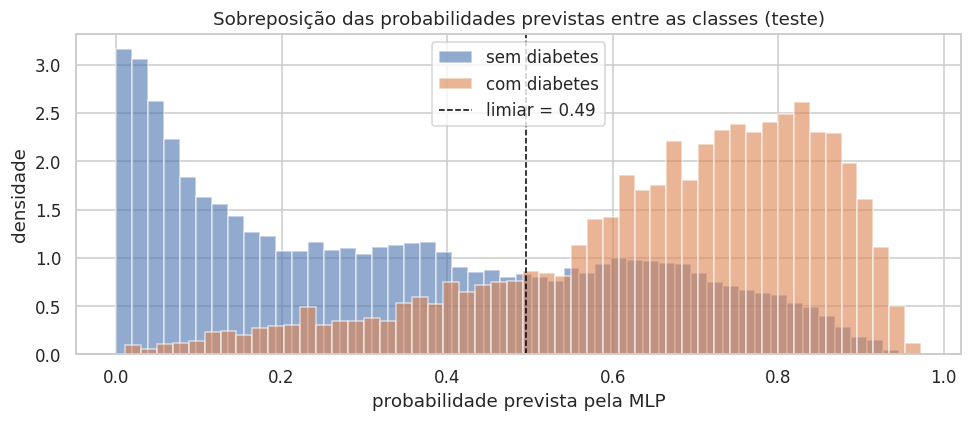

In [17]:
# ============================================================
# 15c. Análise dos erros: perfil de cada célula da matriz de confusão
# ============================================================
pred_te = (prob_mlp_te >= lim_mlp).astype(int)
ordem = ["VP (diabetes detectado)", "FN (diabetes não detectado)", "FP (alarme falso)", "VN (sem diabetes, correto)"]
grupo = np.select([(y_test == 1) & (pred_te == 1), (y_test == 1) & (pred_te == 0),
                   (y_test == 0) & (pred_te == 1), (y_test == 0) & (pred_te == 0)], ordem, default="")

te = X_test.copy()                      # valores ORIGINAIS (não padronizados), mais fáceis de interpretar
te["grupo"], te["prob"], te["real"] = grupo, prob_mlp_te, y_test
cols_perfil = ["prob", "GenHlth", "BMI", "Age", "HighBP", "HighChol", "DiffWalk",
               "HeartDiseaseorAttack", "PhysActivity", "Income"]
perfil = te.groupby("grupo")[cols_perfil].mean().reindex(ordem)
perfil.insert(0, "n", te["grupo"].value_counts().reindex(ordem))
print("Médias por grupo (binárias = proporção; GenHlth 1–5; Age 1–13; Income 1–8):")
display(perfil.round(2))

# Distribuição das probabilidades previstas para quem tem e quem não tem diabetes
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(prob_mlp_te[y_test == 0], bins=50, alpha=0.6, density=True, label="sem diabetes", color="#4C72B0")
ax.hist(prob_mlp_te[y_test == 1], bins=50, alpha=0.6, density=True, label="com diabetes", color="#DD8452")
ax.axvline(lim_mlp, ls="--", color="black", lw=1, label=f"limiar = {lim_mlp:.2f}")
ax.set_xlabel("probabilidade prevista pela MLP"); ax.set_ylabel("densidade")
ax.set_title("Sobreposição das probabilidades previstas entre as classes (teste)"); ax.legend()
plt.tight_layout(); plt.show()

In [18]:
# ============================================================
# 15d. Desempenho por subgrupo (teste, limiar de Youden)
# ============================================================
def metricas_grupo(mask, rotulo, categoria):
    yy, pp = y_test[mask], prob_mlp_te[mask]
    pr = (pp >= lim_mlp).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pr, labels=[0, 1]).ravel()
    return {"variável": rotulo, "grupo": categoria, "n": int(mask.sum()), "prevalência": yy.mean(),
            "ROC-AUC": roc_auc_score(yy, pp), "Sensibilidade": tp / (tp + fn),
            "Especificidade": tn / (tn + fp), "Precisão": tp / (tp + fp) if (tp + fp) else np.nan}

faixa_idade = pd.cut(X_test["Age"], bins=[0, 5, 9, 13], labels=["18–44 anos", "45–64 anos", "65 anos ou mais"])
faixa_imc = pd.cut(X_test["BMI"], bins=[0, 25, 30, 200], right=False, labels=["< 25", "25–29,9", "≥ 30"])
faixa_saude = pd.cut(X_test["GenHlth"], bins=[0, 2, 3, 5], labels=["excelente/muito boa", "boa", "regular/ruim"])

linhas = []
for rot, serie in [("Sexo", X_test["Sex"].map({0: "feminino", 1: "masculino"})), ("Idade", faixa_idade),
                   ("IMC", faixa_imc), ("Saúde geral", faixa_saude)]:
    for cat in serie.cat.categories if hasattr(serie, "cat") else sorted(serie.unique()):
        linhas.append(metricas_grupo((serie == cat).values, rot, cat))
tab_sub = pd.DataFrame(linhas)
display(tab_sub.round(3))

,variável,grupo,n,prevalência,ROC-AUC,Sensibilidade,Especificidade,Precisão
0,Sexo,feminino,21321,0.130,0.843,0.798,0.734,0.310
1,Sexo,masculino,16731,0.151,0.813,0.835,0.650,0.298
2,Idade,18–44 anos,8382,0.044,0.868,0.469,0.945,0.282
3,Idade,45–64 anos,16327,0.136,0.830,0.803,0.718,0.310
4,Idade,65 anos ou mais,13343,0.203,0.764,0.872,0.483,0.301
5,IMC,< 25,10874,0.055,0.842,0.536,0.891,0.222
6,IMC,"25–29,9",14046,0.116,0.808,0.753,0.721,0.262
7,IMC,≥ 30,13132,0.234,0.778,0.902,0.470,0.343
8,Saúde geral,excelente/muito boa,20123,0.056,0.822,0.493,0.891,0.211
9,Saúde geral,boa,11411,0.177,0.750,0.841,0.512,0.271


,n,risco_previsto,proporcao_observada
decil,,,
1,3806,0.003,0.004
2,3805,0.010,0.007
3,3805,0.022,0.021
4,3805,0.041,0.044
5,3805,0.067,0.053
6,3805,0.100,0.098
7,3805,0.152,0.153
8,3805,0.216,0.224
9,3805,0.300,0.316


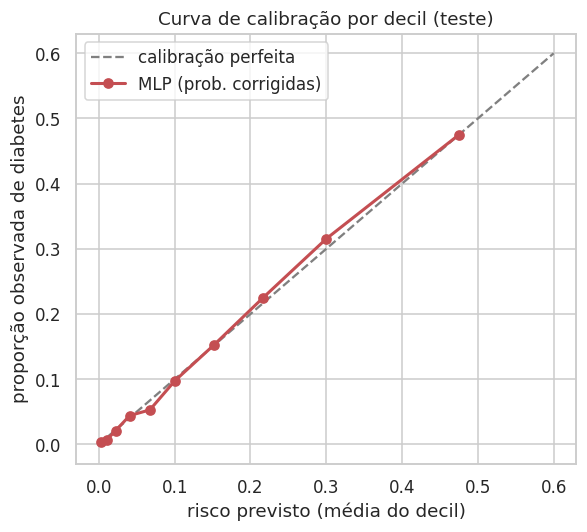

Proporção acumulada dos casos de diabetes capturada pelos decis de maior risco:
decil
10    0.341
9     0.567
8     0.728
7     0.838
6     0.908
5     0.946
4     0.978
3     0.993
2     0.997
1     1.000


In [19]:
# ============================================================
# 15e. Calibração das probabilidades corrigidas (decis de risco)
# ============================================================
p_corr = corrigir_prob(prob_mlp_te)
decil = pd.qcut(p_corr, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"decil": decil + 1, "previsto": p_corr, "observado": y_test}).groupby("decil").agg(
    n=("observado", "size"), risco_previsto=("previsto", "mean"), proporcao_observada=("observado", "mean"))
display(calib.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.6], [0, 0.6], ls="--", color="gray", label="calibração perfeita")
ax.plot(calib["risco_previsto"], calib["proporcao_observada"], "o-", color="#C44E52", lw=2, label="MLP (prob. corrigidas)")
ax.set_xlabel("risco previsto (média do decil)"); ax.set_ylabel("proporção observada de diabetes")
ax.set_title("Curva de calibração por decil (teste)"); ax.legend()
plt.tight_layout(); plt.show()

# Quanto do total de casos fica nos decis de maior risco?
casos_top = calib.sort_index(ascending=False)
acum = (casos_top["proporcao_observada"] * casos_top["n"]).cumsum() / y_test.sum()
print("Proporção acumulada dos casos de diabetes capturada pelos decis de maior risco:")
print(acum.round(3).to_string())

In [20]:
# ============================================================
# 15f. Exemplos de previsões individuais (conjunto de teste)
# ============================================================
te["prob_corrigida"] = p_corr
exemplos = pd.concat([
    te[te["grupo"] == ordem[0]].nlargest(1, "prob"),                         # VP com maior probabilidade
    te[te["grupo"] == ordem[0]].nsmallest(1, "prob"),                        # VP próximo do limiar
    te[te["grupo"] == ordem[1]].nsmallest(1, "prob"),                        # FN com menor probabilidade
    te[te["grupo"] == ordem[2]].nlargest(1, "prob"),                         # FP com maior probabilidade
    te[te["grupo"] == ordem[3]].nsmallest(1, "prob"),                        # VN com menor probabilidade
])
cols_ex = ["grupo", "real", "prob", "prob_corrigida", "GenHlth", "BMI", "Age", "HighBP", "HighChol",
           "DiffWalk", "HeartDiseaseorAttack", "CholCheck", "Income"]
display(exemplos[cols_ex].round(3))

,grupo,real,prob,prob_corrigida,GenHlth,BMI,Age,HighBP,HighChol,DiffWalk,HeartDiseaseorAttack,CholCheck,Income
210076,VP (diabetes detectado),1,0.973,0.853,5.0,48.0,10.0,1.0,1.0,1.0,1.0,1.0,5.0
55532,VP (diabetes detectado),1,0.495,0.137,3.0,30.0,7.0,0.0,1.0,0.0,0.0,1.0,7.0
220269,FN (diabetes não detectado),1,0.011,0.002,1.0,20.0,2.0,0.0,0.0,0.0,0.0,1.0,7.0
240097,FP (alarme falso),0,0.965,0.817,5.0,64.0,12.0,1.0,1.0,1.0,1.0,1.0,4.0
135758,"VN (sem diabetes, correto)",0,0.000,0.000,1.0,19.0,4.0,0.0,0.0,0.0,0.0,0.0,8.0


**O que essas análises mostram**

- **Os falsos negativos são pessoas com diabetes que "não parecem" ter diabetes.** Comparadas aos verdadeiros positivos, elas relatam saúde geral melhor (2,4 × 3,5), têm IMC menor (27,9 × 32,9), são mais jovens, têm menos pressão alta (36% × 84%) e menos colesterol alto (42% × 72%), praticam mais atividade física e têm renda maior. Ou seja, o modelo erra justamente nos casos em que os sinais de risco autorrelatados estão ausentes. O exemplo mais extremo é uma pessoa de 25–29 anos, com IMC 20 e saúde excelente, que tem diabetes; nesses casos, informações como histórico familiar ou exames laboratoriais seriam necessárias.
- **Os falsos positivos são o espelho disso:** pessoas sem diabetes com perfil de risco muito parecido com o de quem tem a doença (IMC médio 31,1; 76% com pressão alta; idade semelhante à dos verdadeiros positivos). Do ponto de vista do rastreio, muitas delas são justamente o público que deveria fazer exames, porque têm alto risco de desenvolver diabetes.
- **As distribuições de probabilidade se sobrepõem bastante**, o que explica por que nenhum limiar consegue separar perfeitamente as classes.
- **O desempenho varia entre subgrupos.** A discriminação é maior em mulheres (AUC 0,843) do que em homens (0,813), e cai com a idade (0,868 em 18–44 anos; 0,764 em 65 anos ou mais), com o IMC (0,842 abaixo de 25; 0,778 acima de 30) e com a pior saúde geral (0,822 → 0,723). A explicação é intuitiva: dentro de grupos em que quase todos têm fatores de risco, fica mais difícil diferenciar quem tem a doença. Com o mesmo limiar, a sensibilidade é baixa entre jovens (47%) e pessoas com IMC normal (54%) e muito alta entre idosos (87%) e pessoas com obesidade (90%), à custa de especificidade. Se o modelo fosse usado na prática, valeria considerar limiares diferentes por grupo.
- **Depois da correção, as probabilidades estão muito bem calibradas:** em todos os decis, o risco previsto é praticamente igual à proporção observada (por exemplo, 47,5% previsto × 47,5% observado no decil de maior risco). Além disso, os 20% de pessoas com maior risco previsto concentram 57% de todos os casos de diabetes, e os 30% de maior risco concentram 73%.

### 3.2 Interpretabilidade: quais variáveis o modelo mais usa?

Para abrir a "caixa-preta", eu uso duas técnicas do Módulo 3:

1. **Importância por permutação:** embaralho uma variável de cada vez no teste e meço **quanto o ROC-AUC cai**. Se embaralhar uma variável derruba o desempenho, o modelo depende dela.
2. **SHAP:** estima a contribuição de cada variável para a predição **de cada pessoa**, mostrando também a **direção** do efeito (se valores altos aumentam ou diminuem o risco).

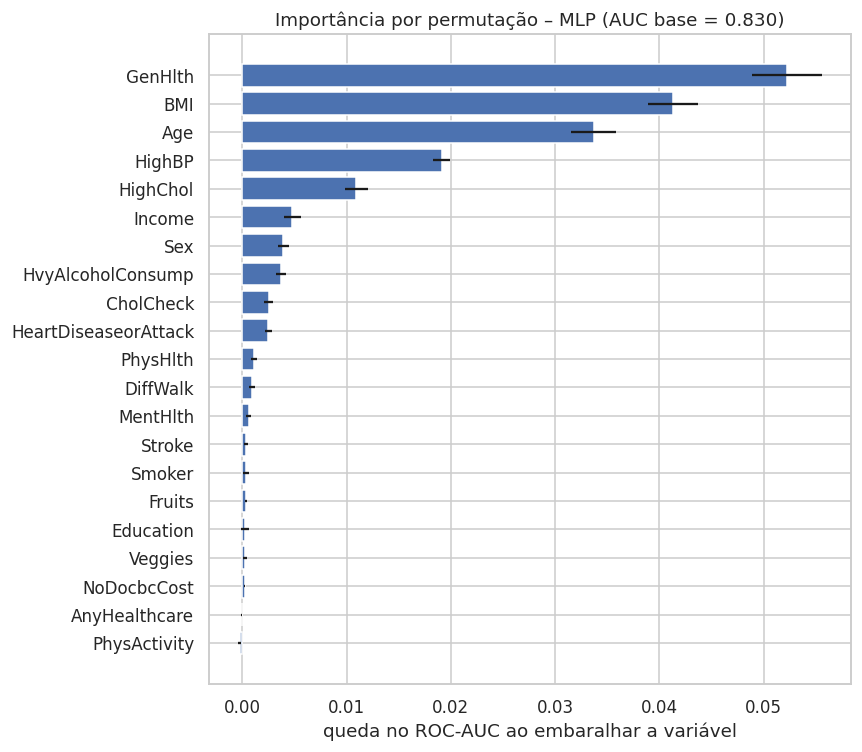

                      queda_media      dp
GenHlth                    0.0523  0.0034
BMI                        0.0413  0.0024
Age                        0.0337  0.0022
HighBP                     0.0191  0.0008
HighChol                   0.0109  0.0011
Income                     0.0048  0.0008
Sex                        0.0039  0.0006
HvyAlcoholConsump          0.0037  0.0005
CholCheck                  0.0025  0.0004
HeartDiseaseorAttack       0.0025  0.0003


In [21]:
# ============================================================
# 16. Importância por permutação (queda no ROC-AUC)
# ============================================================
rng = np.random.default_rng(SEED)
idx_amostra = rng.choice(len(Xte), size=15000, replace=False)
Xp, yp = Xte[idx_amostra], y_test[idx_amostra]
auc_base = roc_auc_score(yp, modelo_final.predict(Xp, batch_size=4096, verbose=0).ravel())

N_REP = 5
importancias = {}
for j, feat in enumerate(FEATURES):
    quedas = []
    for _ in range(N_REP):
        Xperm = Xp.copy()
        Xperm[:, j] = rng.permutation(Xperm[:, j])
        quedas.append(auc_base - roc_auc_score(yp, modelo_final.predict(Xperm, batch_size=4096, verbose=0).ravel()))
    importancias[feat] = (np.mean(quedas), np.std(quedas))

imp = pd.DataFrame(importancias, index=["queda_media", "dp"]).T.sort_values("queda_media")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp["queda_media"], xerr=imp["dp"], color="#4C72B0")
ax.set_xlabel("queda no ROC-AUC ao embaralhar a variável")
ax.set_title(f"Importância por permutação – MLP (AUC base = {auc_base:.3f})")
plt.tight_layout(); plt.show()
print(imp.sort_values("queda_media", ascending=False).round(4).head(10).to_string())

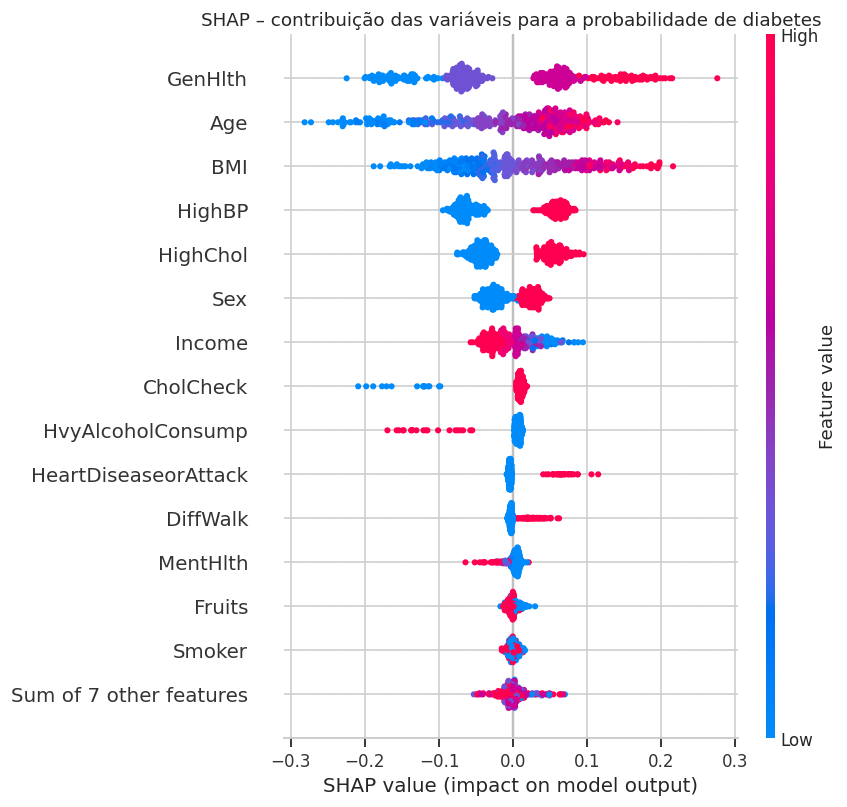

In [22]:
# ============================================================
# 17. SHAP (direção e magnitude do efeito de cada variável)
# ============================================================
import shap
fundo = Xtr[rng.choice(len(Xtr), size=100, replace=False)]       # amostra de referência
explicar = Xte[rng.choice(len(Xte), size=400, replace=False)]    # pessoas a explicar
f = lambda x: modelo_final.predict(x, batch_size=8192, verbose=0).ravel()

explainer = shap.PermutationExplainer(f, shap.maskers.Independent(fundo), feature_names=FEATURES)
shap_values = explainer(explicar, max_evals=2 * len(FEATURES) + 1, silent=True)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP – contribuição das variáveis para a probabilidade de diabetes")
plt.tight_layout(); plt.show()
# Leitura: cada ponto é uma pessoa; à direita = aumenta o risco previsto.
# Cor vermelha = valor alto da variável (na escala padronizada para as não binárias).

**O que a interpretabilidade mostra**

- **Poucas variáveis concentram a informação.** Na importância por permutação, embaralhar **saúde geral** derruba o ROC-AUC em ~0,052, **IMC** em ~0,041 e **idade** em ~0,034, seguidas de **pressão alta** (~0,019) e **colesterol alto** (~0,011). Todas as outras variáveis contribuem com menos de 0,005. Isso é coerente com a análise exploratória e com o conhecimento clínico sobre fatores de risco para diabetes tipo 2.
- **Direção dos efeitos (SHAP):** valores altos de saúde geral (pior saúde autorrelatada), idade e IMC **aumentam** o risco previsto; ter pressão alta, colesterol alto, doença cardíaca ou dificuldade para caminhar também aumenta; **renda mais alta diminui** o risco previsto.
- **Dois achados "contraintuitivos" que valem discussão:**
  - **Não ter feito exame de colesterol nos últimos 5 anos (`CholCheck` = 0) diminui o risco previsto.** A explicação mais provável é um **viés de detecção**: quem tem menos contato com serviços de saúde também tem menos chance de *ter sido diagnosticado*. Vale lembrar que o alvo é o **diagnóstico autorrelatado**, e não a doença em si.
  - **Consumo pesado de álcool diminui o risco previsto.** Isso não significa que o álcool proteja contra o diabetes. É provável que reflita **causalidade reversa** (pessoas já diagnosticadas são orientadas a reduzir o álcool) ou confundimento.

> Esses dois casos mostram por que a interpretabilidade é importante: o modelo aprende **associações presentes nos dados**, inclusive vieses de coleta, e não mecanismos causais.

*Observação metodológica:* a importância por permutação pode subestimar variáveis correlacionadas entre si (quando uma é embaralhada, a outra "cobre" parte da informação). Por isso eu uso as duas técnicas de forma complementar.

## 4. Conclusão

1. Uma **MLP com 3 camadas ocultas, Dropout e Early Stopping** estimou o risco de diabetes a partir de 21 indicadores autorrelatados com **ROC-AUC de 0,830** e **PR-AUC de 0,428** no teste (o acaso seria 0,14). Com o limiar escolhido na validação, o modelo detecta **~82% das pessoas com diabetes**, com especificidade de ~70%.
2. A rede neural superou a regressão logística de forma **consistente, mas modesta** (+0,008 de ROC-AUC; +0,032 de PR-AUC). Em dados tabulares com relações predominantemente aditivas, um modelo linear bem ajustado já é um concorrente forte.
3. **Regularização foi decisiva:** sem ela, a rede sobreajustou e ficou pior que o baseline. O **Early Stopping** sozinho trouxe o maior ganho; Dropout e L2 adiaram o sobreajuste e deram pequenos ganhos adicionais; o Batch Normalization acelerou a convergência sem melhorar o desempenho; combinar tudo não trouxe benefício extra.
4. **Otimizadores adaptativos** (Adam, RMSProp) convergiram em 13–18 épocas, enquanto SGD e SGD + Momentum ainda não tinham convergido após 60 épocas.
5. As variáveis mais influentes foram **saúde geral, IMC, idade, pressão alta e colesterol**.

**Limitações**
- Dados **transversais e autorrelatados**: o alvo é o diagnóstico informado pela pessoa, sujeito a subdiagnóstico e a viés de memória. As associações não são causais.
- Os dados são de **2015 e dos EUA**; a generalização para outras populações (por exemplo, a brasileira) precisaria ser testada.
- Por causa dos pesos de classe, as probabilidades do modelo **não estão calibradas** para a prevalência real; para usá-las como risco absoluto seria preciso calibrar (por exemplo, com *Platt scaling*).
- As diferenças entre as configurações regularizadas são pequenas, e eu não repeti os experimentos com várias sementes para estimar a variabilidade.

**Trabalhos futuros:** repetir os experimentos com várias sementes ou com validação cruzada; testar modelos baseados em árvores (por exemplo, *gradient boosting*) como comparação; calibrar as probabilidades; explorar o problema de 3 classes (incluindo o pré-diabetes) com técnicas para classes raras.

## 5. Referências


CENTERS FOR DISEASE CONTROL AND PREVENTION (CDC). **Behavioral Risk Factor Surveillance System Survey Data**. Atlanta: U.S. Department of Health and Human Services, 2015.

CHOLLET, F. **Deep learning with Python**. 2. ed. Shelter Island: Manning, 2021.

GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. **Deep learning**. Cambridge: MIT Press, 2016.

IOFFE, S.; SZEGEDY, C. Batch normalization: accelerating deep network training by reducing internal covariate shift. In: INTERNATIONAL CONFERENCE ON MACHINE LEARNING, 32., 2015, Lille. **Proceedings** [...]. PMLR, 2015. v. 37, p. 448–456.

KINGMA, D. P.; BA, J. Adam: a method for stochastic optimization. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS, 3., 2015, San Diego. **Proceedings** [...]. 2015. arXiv:1412.6980.

LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. In: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS, 30., 2017, Long Beach. **Proceedings** [...]. 2017. p. 4765–4774.

SRIVASTAVA, N. et al. Dropout: a simple way to prevent neural networks from overfitting. **Journal of Machine Learning Research**, v. 15, n. 1, p. 1929–1958, 2014.

TEBOUL, A. **Diabetes Health Indicators Dataset**. Kaggle, 2021. Disponível em: https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset. Acesso em: 6 nov. 2026.

XIE, Z. et al. Building risk prediction models for type 2 diabetes using machine learning techniques. **Preventing Chronic Disease**, v. 16, E130, 2019.

YOUDEN, W. J. Index for rating diagnostic tests. **Cancer**, v. 3, n. 1, p. 32–35, 1950.

## Apêndice – Figuras do relatório

As figuras do relatório final foram geradas pelo código abaixo, a partir dos resultados obtidos neste notebook. Usei um estilo visual único (cores, fontes e rótulos em português) para que os gráficos fiquem legíveis no documento. Os dados são exatamente os mesmos dos gráficos exploratórios das seções anteriores. As figuras são salvas na pasta `figuras_relatorio/`, na mesma numeração do relatório (Figuras 1 a 12).

In [23]:
# ============================================================
# 18. Funções que desenham as figuras do relatório
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch

PASTA_FIG = "figuras_relatorio"
os.makedirs(PASTA_FIG, exist_ok=True)

AZUL, LARANJA, VERDE_AGUA, VIOLETA, ROSA, VERMELHO, VERDE = (
    "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4", "#e34948", "#008300")
TINTA, TINTA2, CINZA, GRADE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
ESTILO = {"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": CINZA, "axes.labelcolor": TINTA2,
          "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.grid": True, "grid.color": GRADE,
          "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
          "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
          "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight"}

def br(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")

def salvar(fig, nome, mostrar=True):
    fig.savefig(os.path.join(PASTA_FIG, nome), facecolor="white")
    if mostrar:
        plt.show()
    plt.close(fig)

def fig_prevalencia(prev, prev_geral):
    titulos = {"GenHlth": "Saúde geral (1 = excelente, 5 = ruim)", "Age": "Faixa etária (1 = 18–24 … 13 = 80+)",
               "BMI_faixa": "IMC (kg/m²)", "Income": "Renda (1 = menor … 8 = maior)",
               "HighBP": "Pressão alta (0 = não, 1 = sim)", "PhysActivity": "Atividade física (0 = não, 1 = sim)"}
    fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
    for ax, (col, t) in zip(axes.ravel(), titulos.items()):
        rot = [str(k).replace(".0", "") for k in prev[col].keys()]
        ax.bar(rot, list(prev[col].values()), color=AZUL, width=0.72)
        ax.axhline(prev_geral * 100, ls="--", color=CINZA, lw=1)
        ax.set_title(t, fontsize=9); ax.set_ylabel("% com diabetes"); ax.grid(axis="x", visible=False)
        if col == "BMI_faixa":
            ax.tick_params(axis="x", labelsize=7)
    fig.text(0.5, -0.01, f"Linha tracejada: prevalência geral ({br(prev_geral * 100, 1)}%)", ha="center", color=TINTA2, fontsize=8)
    fig.tight_layout(); return fig

def fig_correlacao(corr):
    corr = dict(sorted(corr.items(), key=lambda kv: kv[1]))
    fig, ax = plt.subplots(figsize=(7, 5.4))
    ax.barh(list(corr.keys()), list(corr.values()), color=[LARANJA if v > 0 else AZUL for v in corr.values()], height=0.7)
    ax.axvline(0, color=TINTA2, lw=0.8); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Correlação com Diabetes_binary (ponto-bisserial)")
    ax.set_title("Associação univariada de cada variável com o diabetes")
    for i, v in enumerate(corr.values()):
        ax.text(v + (0.004 if v >= 0 else -0.004), i, br(v, 2), va="center", ha="left" if v >= 0 else "right", fontsize=7, color=TINTA2)
    fig.tight_layout(); return fig

def fig_arquitetura(n_entrada, camadas, dropout, n_parametros):
    blocos = [(f"Entrada\n{n_entrada} variáveis", "#eef3fb")]
    blocos += [(f"Densa {n}\nReLU\n+ Dropout {int(dropout * 100)}%", "#dce8f8") for n in camadas]
    blocos += [("Saída 1\nSigmoide\nP(diabetes)", "#fde8de")]
    fig, ax = plt.subplots(figsize=(10, 2.3)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 2.3)
    xs = np.linspace(0.15, 8.15, len(blocos))
    for x, (txt, cor) in zip(xs, blocos):
        ax.add_patch(FancyBboxPatch((x, 0.35), 1.7, 1.6, boxstyle="round,pad=0.02,rounding_size=0.12", fc=cor, ec=TINTA2, lw=0.8))
        ax.text(x + 0.85, 1.15, txt, ha="center", va="center", fontsize=8.5, color=TINTA)
    for x in xs[:-1]:
        ax.annotate("", xy=(x + 2.0, 1.15), xytext=(x + 1.72, 1.15), arrowprops=dict(arrowstyle="->", color=TINTA2, lw=1))
    ax.text(5, 0.08, f"{n_parametros:,} parâmetros treináveis · perda: entropia cruzada binária ponderada · otimizador: Adam (lr = 0,001) · batch = 1024".replace(",", "."),
            ha="center", fontsize=8, color=TINTA2)
    return fig

def fig_curvas(hist, melhor):
    fig, axes = plt.subplots(2, 3, figsize=(10, 5.8))
    for ax, (nome, h) in zip(axes.ravel(), hist.items()):
        ep = np.arange(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], color=AZUL, lw=1.8, label="treino")
        ax.plot(ep, h["val_loss"], color=LARANJA, lw=1.8, label="validação")
        b = melhor[nome]
        ax.axvline(b, ls=":", color=CINZA); ax.scatter([b], [h["val_loss"][b - 1]], color=LARANJA, s=18, zorder=5)
        ax.set_title(f"{nome}\nmelhor época = {b}", fontsize=8.5); ax.set_xlabel("época", fontsize=8); ax.set_ylabel("perda", fontsize=8)
    axes[0, 0].legend(fontsize=7.5, loc="upper left")
    fig.tight_layout(); return fig

def fig_curvas_zoom(hist):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for (nome, h), c in zip(hist.items(), [AZUL, LARANJA, VERDE_AGUA, VIOLETA, ROSA, VERMELHO]):
        vl = list(h["val_loss"])
        if nome.startswith("A"):
            vl = vl[:30]
        ax.plot(np.arange(1, len(vl) + 1), vl, color=c, lw=1.8, label=nome)
    ax.set_ylim(0.495, 0.56); ax.set_xlabel("época"); ax.set_ylabel("perda na validação")
    ax.set_title("Perda de validação por época (zoom; A mostrado até a época 30)"); ax.legend(fontsize=7.5, ncol=2)
    fig.tight_layout(); return fig

def fig_otimizadores(hist_opt):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for (nome, h), c in zip(hist_opt.items(), [CINZA, VIOLETA, VERDE_AGUA, AZUL]):
        ep = np.arange(1, len(h["val_loss"]) + 1)
        axes[0].plot(ep, h["val_loss"], color=c, lw=1.8, label=nome)
        axes[1].plot(ep, h["val_auc"], color=c, lw=1.8, label=nome)
    axes[0].set_title("Perda na validação"); axes[0].set_xlabel("época"); axes[0].set_ylabel("perda")
    axes[1].set_title("ROC-AUC na validação"); axes[1].set_xlabel("época"); axes[1].set_ylabel("ROC-AUC")
    axes[0].legend(fontsize=7.5); fig.tight_layout(); return fig

def fig_limiar(lim_dict, limiar_youden):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for met, c in [("Sensibilidade", VERMELHO), ("Especificidade", AZUL), ("Precisão", VERDE), ("F1", VIOLETA)]:
        ax.plot(lim_dict["limiar"], lim_dict[met], color=c, lw=1.8, label=met)
    ax.axvline(limiar_youden, ls="--", color=TINTA, lw=1, label=f"Youden = {br(limiar_youden, 2)}")
    ax.set_xlabel("limiar de decisão"); ax.set_ylabel("valor"); ax.set_title("Efeito do limiar de decisão (MLP, validação)")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5)
    fig.tight_layout(); return fig

def fig_teste(roc_mlp, roc_lr, pr_mlp, pr_lr, auc_mlp, auc_lr, ap_mlp, ap_lr, prevalencia, cm, limiar):
    grid = np.linspace(0, 1, len(roc_mlp))
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
    axes[0].plot(grid, roc_mlp, color=AZUL, lw=1.8, label=f"MLP (AUC = {br(auc_mlp)})")
    axes[0].plot(grid, roc_lr, color=LARANJA, lw=1.8, label=f"Reg. logística (AUC = {br(auc_lr)})")
    axes[0].plot([0, 1], [0, 1], ls="--", color=CINZA, lw=1, label="acaso")
    axes[0].set_xlabel("1 − especificidade"); axes[0].set_ylabel("sensibilidade"); axes[0].set_title("Curva ROC (teste)"); axes[0].legend(fontsize=7)
    axes[1].plot(grid[1:], pr_mlp[1:], color=AZUL, lw=1.8, label=f"MLP (AP = {br(ap_mlp)})")
    axes[1].plot(grid[1:], pr_lr[1:], color=LARANJA, lw=1.8, label=f"Reg. logística (AP = {br(ap_lr)})")
    axes[1].axhline(prevalencia, ls="--", color=CINZA, lw=1, label=f"acaso ({br(prevalencia, 2)})")
    axes[1].set_xlabel("sensibilidade (recall)"); axes[1].set_ylabel("precisão"); axes[1].set_title("Curva precisão–sensibilidade (teste)")
    axes[1].set_ylim(0, 1); axes[1].legend(fontsize=7)
    cm = np.array(cm); ax = axes[2]; ax.grid(False); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > cm.max() / 2 else TINTA, fontweight="bold")
    ax.set_xticks([0, 1], ["prevê: sem", "prevê: diabetes"]); ax.set_yticks([0, 1], ["real: sem", "real: diabetes"])
    ax.set_title(f"Matriz de confusão – MLP (limiar {br(limiar, 2)})")
    for s in ax.spines.values():
        s.set_visible(False)
    fig.tight_layout(); return fig

def fig_sobreposicao(centros, dens0, dens1, limiar):
    largura = centros[1] - centros[0]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.bar(centros, dens0, width=largura, color=AZUL, alpha=0.55, label="sem diabetes", edgecolor="white", linewidth=0.5)
    ax.bar(centros, dens1, width=largura, color=LARANJA, alpha=0.55, label="com diabetes", edgecolor="white", linewidth=0.5)
    ax.axvline(limiar, ls="--", color="black", lw=1, label=f"limiar = {br(limiar, 2)}")
    ax.set_xlabel("probabilidade prevista pela MLP (sem correção)"); ax.set_ylabel("densidade")
    ax.set_title("Distribuição das probabilidades previstas por classe (teste)"); ax.legend(fontsize=8)
    fig.tight_layout(); return fig

def fig_calibracao(previsto, observado):
    fig, ax = plt.subplots(figsize=(5, 4.4))
    lim = max(max(previsto), max(observado)) * 1.15
    ax.plot([0, lim], [0, lim], ls="--", color=CINZA, lw=1, label="calibração perfeita")
    ax.plot(previsto, observado, "o-", color=VERMELHO, lw=1.8, ms=5, label="MLP (probabilidades corrigidas)")
    for i, (x, y) in enumerate(zip(previsto, observado)):
        if i >= len(previsto) - 4:
            ax.annotate(f"D{i + 1}", (x, y), textcoords="offset points", xytext=(-14, 6), fontsize=7, color=TINTA2)
    ax.set_xlabel("risco previsto (média do decil)"); ax.set_ylabel("proporção observada de diabetes")
    ax.set_title("Curva de calibração por decil de risco (teste)"); ax.legend(fontsize=8, loc="upper left")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    fig.tight_layout(); return fig

def fig_permutacao(imp):
    imp = dict(sorted(imp.items(), key=lambda kv: kv[1][0]))
    fig, ax = plt.subplots(figsize=(7, 5.2))
    ax.barh(list(imp.keys()), [v[0] for v in imp.values()], xerr=[v[1] for v in imp.values()], color=AZUL, height=0.7,
            error_kw=dict(ecolor=TINTA2, lw=0.8))
    ax.grid(axis="y", visible=False); ax.set_xlabel("queda no ROC-AUC ao embaralhar a variável")
    ax.set_title("Importância por permutação (MLP, teste)")
    fig.tight_layout(); return fig

def fig_shap(shap_resumo):
    sh = dict(sorted(shap_resumo.items(), key=lambda kv: kv[1][0]))
    fig, ax = plt.subplots(figsize=(7, 5.2))
    cores = [LARANJA if v[1] > 0.1 else (AZUL if v[1] < -0.1 else CINZA) for v in sh.values()]
    ax.barh(list(sh.keys()), [v[0] for v in sh.values()], color=cores, height=0.7)
    ax.grid(axis="y", visible=False); ax.set_xlabel("média do |valor SHAP| (impacto na probabilidade prevista)")
    ax.set_title("SHAP: magnitude e direção do efeito de cada variável")
    ax.legend(handles=[Patch(color=LARANJA, label="valor alto → aumenta o risco"),
                       Patch(color=AZUL, label="valor alto → diminui o risco"),
                       Patch(color=CINZA, label="direção pouco clara")], fontsize=7.5, loc="lower right")
    fig.tight_layout(); return fig

def gerar_figuras(R, mostrar=True):
    """Gera e salva as 12 figuras do relatório a partir do dicionário de resultados R."""
    with plt.rc_context(ESTILO):
        salvar(fig_prevalencia(R["prev"], R["prev_geral"]), "fig01_prevalencia.png", mostrar)
        salvar(fig_correlacao(R["corr"]), "fig02_correlacao.png", mostrar)
        salvar(fig_arquitetura(*R["arq"]), "fig03_arquitetura.png", mostrar)
        salvar(fig_curvas(R["hist"], R["melhor"]), "fig04_curvas.png", mostrar)
        salvar(fig_curvas_zoom(R["hist"]), "fig05_curvas_zoom.png", mostrar)
        salvar(fig_otimizadores(R["hist_opt"]), "fig06_otimizadores.png", mostrar)
        salvar(fig_limiar(R["limiar"], R["lim"][0]), "fig07_limiar.png", mostrar)
        salvar(fig_teste(*R["teste"]), "fig08_teste.png", mostrar)
        salvar(fig_sobreposicao(*R["sobreposicao"]), "fig09_sobreposicao.png", mostrar)
        salvar(fig_calibracao(*R["calibracao"]), "fig10_calibracao.png", mostrar)
        salvar(fig_permutacao(R["imp"]), "fig11_permutacao.png", mostrar)
        salvar(fig_shap(R["shap"]), "fig12_shap.png", mostrar)
    print("Figuras salvas em:", os.path.abspath(PASTA_FIG), "->", sorted(os.listdir(PASTA_FIG)))

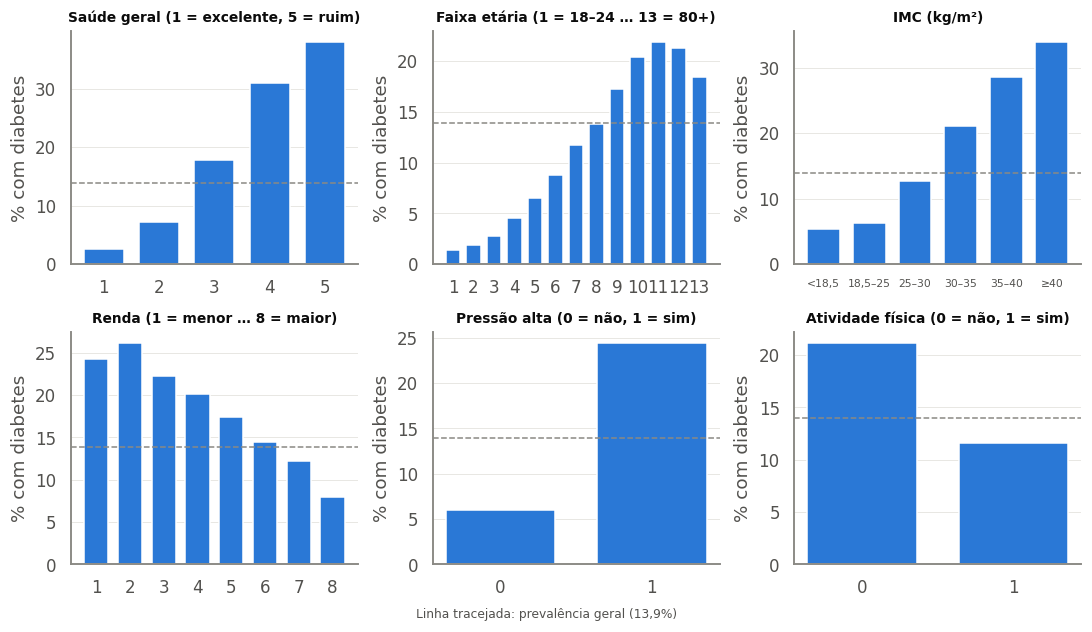

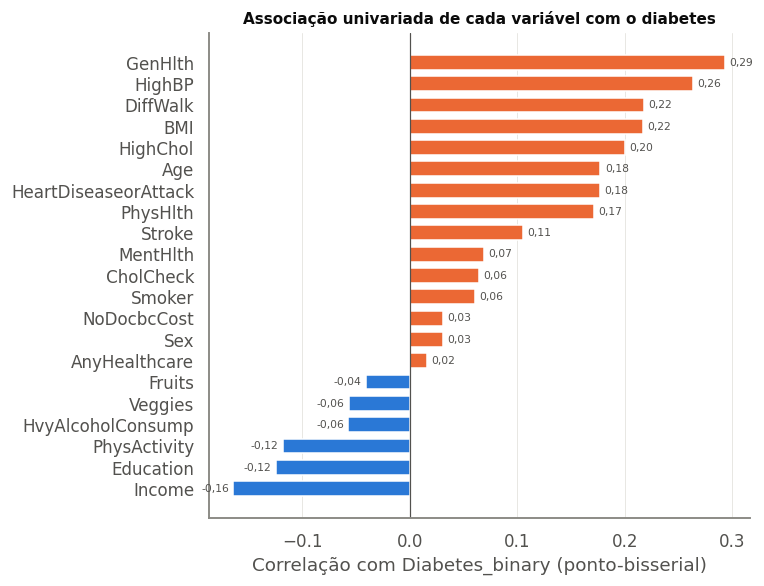

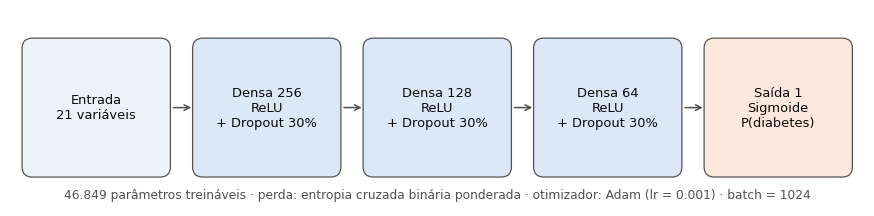

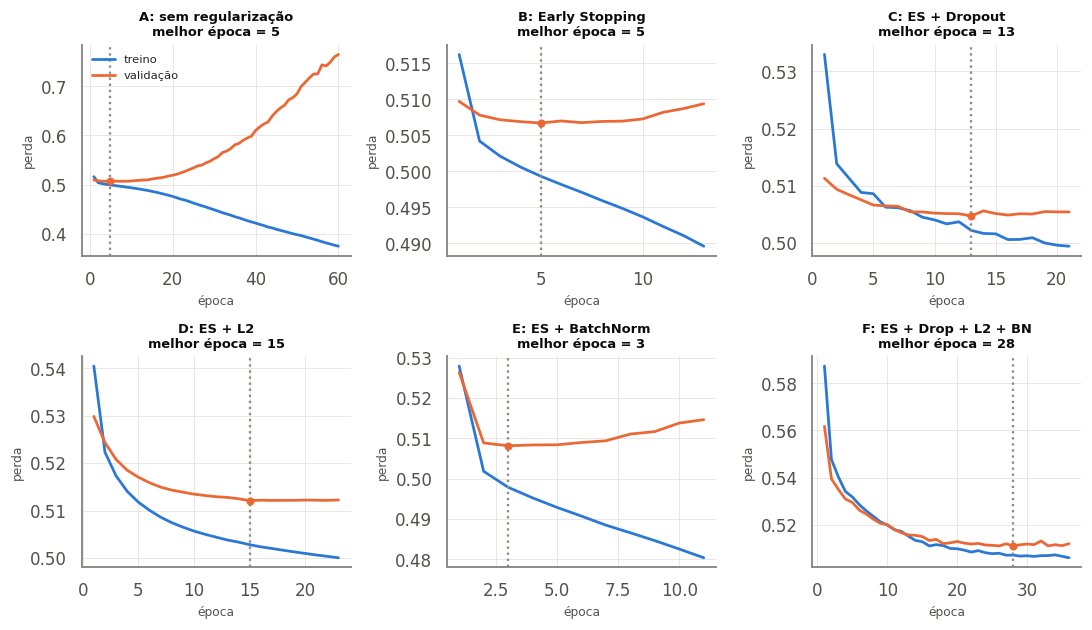

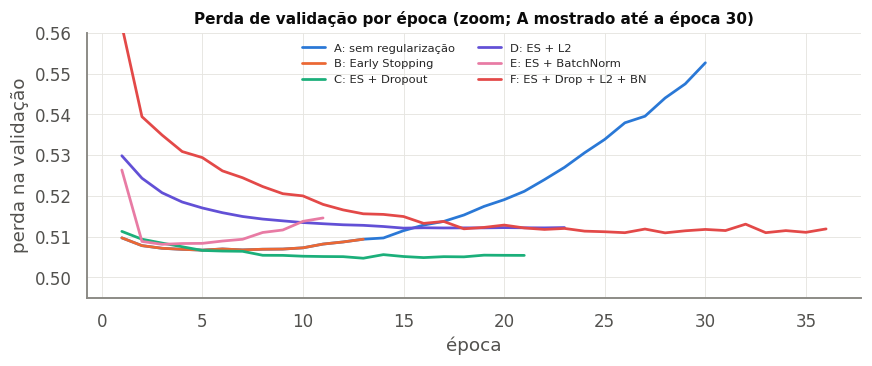

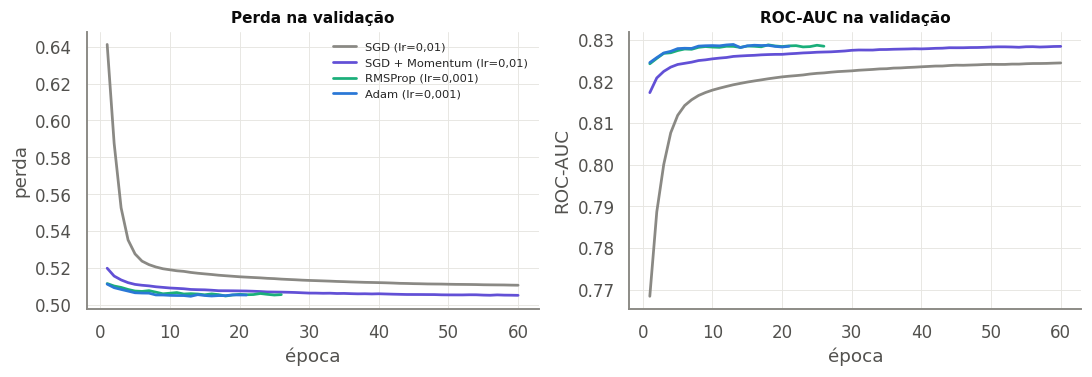

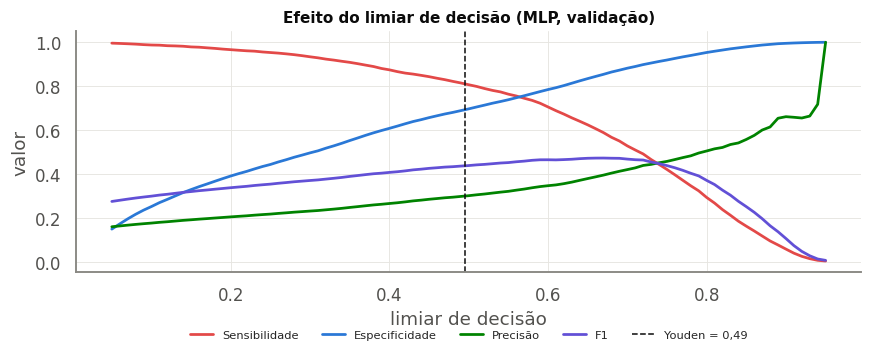

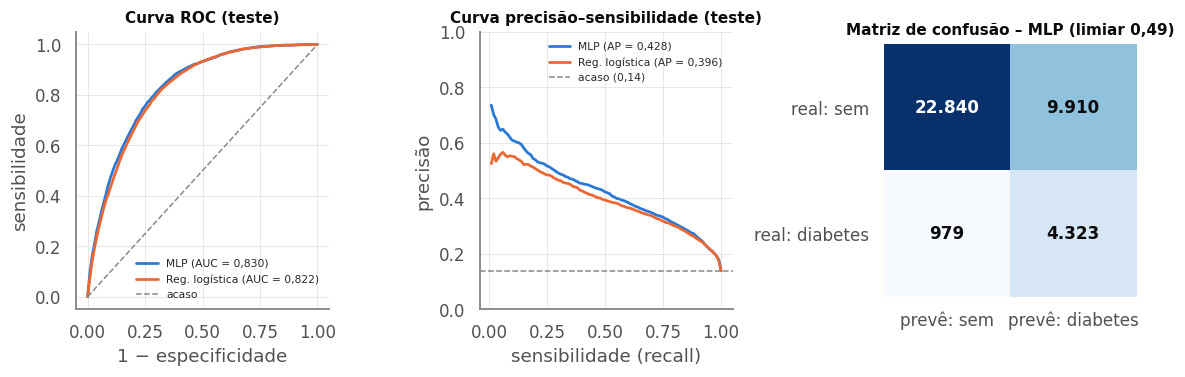

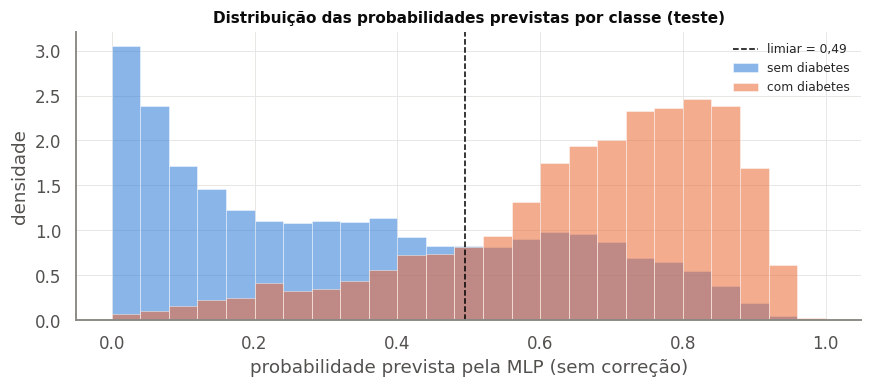

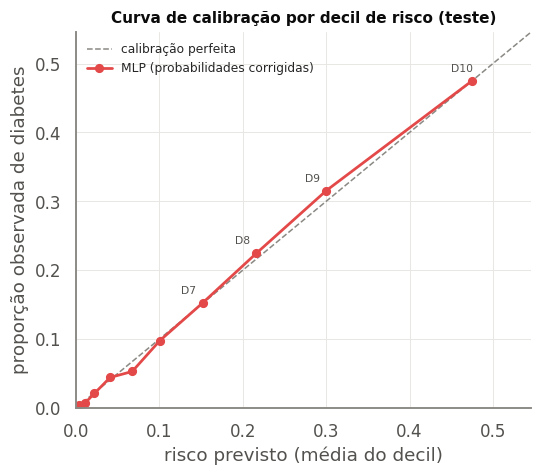

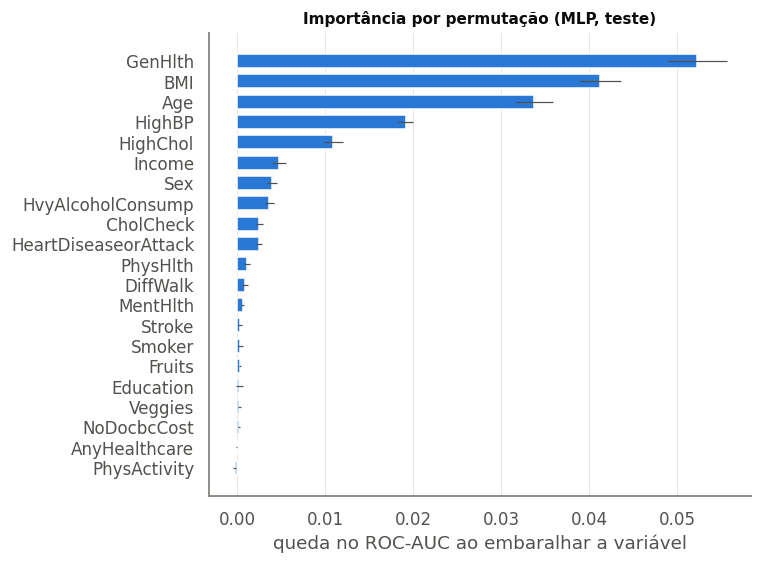

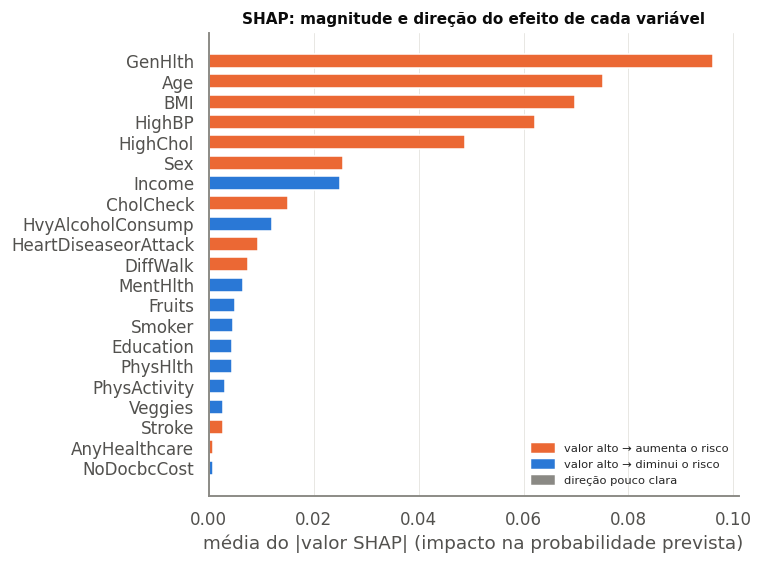

Figuras salvas em: /content/figuras_relatorio -> ['fig01_prevalencia.png', 'fig02_correlacao.png', 'fig03_arquitetura.png', 'fig04_curvas.png', 'fig05_curvas_zoom.png', 'fig06_otimizadores.png', 'fig07_limiar.png', 'fig08_teste.png', 'fig09_sobreposicao.png', 'fig10_calibracao.png', 'fig11_permutacao.png', 'fig12_shap.png']


In [24]:
# ============================================================
# 19. Reunindo os resultados do notebook e gerando as 12 figuras
# ============================================================
grid = np.linspace(0, 1, 101)
curvas_teste = {}
for nome, p in [("mlp", prob_mlp_te), ("lr", prob_lr_te)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    curvas_teste["roc_" + nome] = np.interp(grid, fpr, tpr)
    prec, rec, _ = precision_recall_curve(y_test, p)
    curvas_teste["pr_" + nome] = np.interp(grid, rec[::-1], prec[::-1])

bordas = np.linspace(0, 1, 26)
centros = (bordas[:-1] + bordas[1:]) / 2
dens0, _ = np.histogram(prob_mlp_te[y_test == 0], bins=bordas, density=True)
dens1, _ = np.histogram(prob_mlp_te[y_test == 1], bins=bordas, density=True)
sv, xv = shap_values.values, shap_values.data

R = {
    "prev": {col: (plot_df.groupby(col, observed=True)[TARGET].mean() * 100).to_dict() for col in variaveis},
    "prev_geral": prev_geral,
    "corr": corr_alvo.to_dict(),
    "arq": (N_FEATURES, (256, 128, 64), 0.3, modelo_final.count_params()),
    "hist": historicos,
    "melhor": {k: int(np.argmin(h["val_loss"])) + 1 for k, h in historicos.items()},
    "hist_opt": hist_opt,
    "limiar": curvas[["limiar", "Sensibilidade", "Especificidade", "Precisão", "F1"]].to_dict("list"),
    "lim": (lim_mlp, lim_lr),
    "teste": (curvas_teste["roc_mlp"], curvas_teste["roc_lr"], curvas_teste["pr_mlp"], curvas_teste["pr_lr"],
              roc_auc_score(y_test, prob_mlp_te), roc_auc_score(y_test, prob_lr_te),
              average_precision_score(y_test, prob_mlp_te), average_precision_score(y_test, prob_lr_te),
              y_test.mean(), confusion_matrix(y_test, (prob_mlp_te >= lim_mlp).astype(int)), lim_mlp),
    "sobreposicao": (centros, dens0, dens1, lim_mlp),
    "calibracao": (calib["risco_previsto"].tolist(), calib["proporcao_observada"].tolist()),
    "imp": {k: (row["queda_media"], row["dp"]) for k, row in imp.iterrows()},
    "shap": {f: (np.abs(sv[:, j]).mean(), np.corrcoef(xv[:, j], sv[:, j])[0, 1] if xv[:, j].std() > 0 else 0.0)
             for j, f in enumerate(FEATURES)},
}
gerar_figuras(R)

# Para baixar todas as figuras de uma vez (opcional):
# !zip -qr figuras_relatorio.zip figuras_relatorio
# from google.colab import files; files.download("figuras_relatorio.zip")